Ввиду объемности вычислительных задач, а также событий с дц, оставил все собранные моедли на [гитхабе](https://github.com/andreiyopt/behavior_scoring), чтобы можно было пропустить строчки с их созданием и оценкой

# <a id='toc1_'></a>[Прогноз возникновения просрочки клиентов "Ва-банк"](#toc0_)

## <a id='toc1_1_'></a>[Подготовка рабочего пространства](#toc0_)

* Дайте этой тетрадке Jupyter название, которое корректно отражает суть проекта.
* Опишите постановку задачи своими словами, коротко зафиксировав основной смысл.
* Опишите данные, которые даны для решения задачи.

### <a id='toc1_1_1_'></a>[Оглавление](#toc0_)

**Table of contents**<a id='toc0_'></a>    
- [Прогноз возникновения просрочки клиентов "Ва-банк"](#toc1_)    
  - [Подготовка рабочего пространства](#toc1_1_)    
    - [Оглавление](#toc1_1_1_)    
    - [Постановка задачи](#toc1_1_2_)    
    - [Описание данных](#toc1_1_3_)    
  - [Перевод бизнес-задачи на язык машинного обучения](#toc1_2_)    
    - [План решения задачи](#toc1_2_1_)    
  - [Загрузка необходимых библиотек](#toc1_3_)    
    - [Настройка окружения](#toc1_3_1_)    
    - [Импорт необходимых библиотек](#toc1_3_2_)    
  - [Загрузка данных](#toc1_4_)    
    - [Загрузка датасетов](#toc1_4_1_)    
    - [Вывод по загрузке данных](#toc1_4_2_)    
  - [Исследовательский анализ данных](#toc1_5_)    
    - [Проверка характеристик данных](#toc1_5_1_)    
      - [Вывод проврерки характеристик](#toc1_5_1_1_)    
    - [Графики](#toc1_5_2_)    
      - [Вывод по графическому анализу](#toc1_5_2_1_)    
    - [Общий вывод по исследовательскому анализу](#toc1_5_3_)    
  - [Объединение таблиц](#toc1_6_)    
    - [Формирование целевой переменной](#toc1_6_1_)    
    - [Создание итоговой таблицы](#toc1_6_2_)    
    - [Вывод объединения таблиц](#toc1_6_3_)    
  - [Создание новых признаков](#toc1_7_)    
    - [Выводы](#toc1_7_1_)    
  - [Анализ итоговой таблицы](#toc1_8_)    
    - [Анализ получившейся таблицы](#toc1_8_1_)    
    - [Характеристики признаков](#toc1_8_2_)    
    - [Баланс целевой переменной](#toc1_8_3_)    
    - [Общие выводы](#toc1_8_4_)    
  - [Моделирование](#toc1_9_)    
    - [Базовые модели](#toc1_9_1_)    
    - [Разделение на обучающую, калибровочную и тестовую выборку](#toc1_9_2_)    
    - [Категоризация данных](#toc1_9_3_)    
    - [Обучение базовых моделей](#toc1_9_4_)    
    - [Оптуна для моделей леса](#toc1_9_5_)    
    - [Сравнение всех моделей](#toc1_9_6_)    
    - [Выводы о работе в разделе "моделирование"](#toc1_9_7_)    
  - [Калибровка модели и пересчёт результатов](#toc1_10_)    
    - [Калибровка](#toc1_10_1_)    
    - [Выводы этапа калибровки](#toc1_10_2_)    
  - [Поиск порога решения](#toc1_11_)    
    - [Расчёт метрик для разных порогов](#toc1_11_1_)    
    - [Выбор порога и проверка требований](#toc1_11_2_)    
    - [Выводы этапа поиска порога решений](#toc1_11_3_)    
  - [Анализ матрицы ошибок](#toc1_12_)    
    - [Предсказание матрицы ошибок](#toc1_12_1_)    
    - [Сравнение метрик](#toc1_12_2_)    
    - [Выводы этапа анализа матрицы ошибок](#toc1_12_3_)    
  - [Фиксирование итоговой модели](#toc1_13_)    
    - [Описание модели](#toc1_13_1_)    
    - [Сохранение модели](#toc1_13_2_)    
  - [Анализ важности признаков](#toc1_14_)    
    - [Важность признаков](#toc1_14_1_)    
    - [Выводы этапа Анализа важности признаков](#toc1_14_2_)    
  - [Выводы по проекту](#toc1_15_)    

<!-- vscode-jupyter-toc-config
	numbering=false
	anchor=true
	flat=false
	minLevel=1
	maxLevel=6
	/vscode-jupyter-toc-config -->
<!-- THIS CELL WILL BE REPLACED ON TOC UPDATE. DO NOT WRITE YOUR TEXT IN THIS CELL -->

### <a id='toc1_1_2_'></a>[Постановка задачи](#toc0_)

Банку «Ва-банк» нужна модель поведенческого скоринга, которая поможет заранее выявлять риск просрочек у действующих заёмщиков.

Необходимо решить задачу бинарной классификации: по информации о клиенте на дату скоринга предсказать, возникнет ли у него в следующие 12 месяцев просрочка длительностью 90 дней и более. Каждое наблюдение соответствует одному клиенту в конкретный месяц.

Итоговое решение — модель случайного леса с откалиброванными вероятностями и подобранным порогом классификации. Требуется достичь следующих показателей:

- **Approval rate ≥ 65%** — доля клиентов, признанных моделью надёжными.
- **Default rate ≤ 2%** — доля фактических дефолтов среди признанных надёжными.
- **Missed defaults rate ≤ 4%** — доля пропущенных моделью дефолтов среди всех фактических дефолтов.

При подготовке данных и оценке модели необходимо учитывать временную структуру и исключать использование информации из будущего.

### <a id='toc1_1_3_'></a>[Описание данных](#toc0_)

Для решения задачи предоставлены восемь таблиц:

| Файл | Содержание |
|---|---|
| `ds_15_loan_payment_credit.csv` | Периоды просрочек клиентов: идентификатор клиента, дата начала периода и длительность просрочки в днях. |
| `ds_15_transactions.csv` | Ежемесячные расходы клиентов по MCC-кодам: маркетплейсы, фастфуд, рестораны, продукты, сервисы Яндекса, бытовая техника, ЖКУ и другие категории. |
| `ds_15_client_description.csv` | Характеристики клиентов на момент регистрации: возраст, семейное положение, наличие иждивенцев и дата регистрации в банке. |
| `ds_15_credit_description.csv` | Месячный доход клиента на момент получения кредита и сумма выданного кредита. |
| `ds_15_mortgage_presence.csv` | Сведения о наличии ипотеки и дате её открытия. |
| `ds_15_credit_rating.csv` | Значения кредитного рейтинга клиентов на определённые даты. |
| `ds_15_macro_data.csv` | Ежемесячные макроэкономические показатели России: учётная ставка, уровень безработицы и инфляция. |
| `ds_15_cohort_grid.csv` | Идентификаторы клиентов и даты проведения поведенческого скоринга. |

На основе этих источников необходимо сформировать единую таблицу, где каждая строка соответствует клиенту на конкретную дату скоринга. Клиентские данные связываются по `ID` с учётом дат, а макроэкономические показатели — по времени.

Признаки должны содержать только информацию, доступную на дату скоринга. Данные о последующих просрочках используются для формирования целевой переменной: возникновение просрочки длительностью от 90 дней в следующие 12 месяцев.

## <a id='toc1_2_'></a>[Перевод бизнес-задачи на язык машинного обучения](#toc0_)

* Напишите, что конкретно будете делать, пользуясь терминами машинного обучения:
  * какие модели будете использовать;
  * какие методы работы с данными применять;
  * как планируете решать поставленную задачу.


### <a id='toc1_2_1_'></a>[План решения задачи](#toc0_)

Будем решать задачу бинарной классификации с временной структурой данных.

1. **Исследование и подготовка данных**
   - Изучим пропуски, дубликаты, выбросы и типы данных в каждой таблице.
   - Объединим источники в таблицу наблюдений «клиент — дата скоринга», используя только информацию, доступную на эту дату.
   - Сформируем целевую переменную: возникновение просрочки длительностью от 90 дней в следующие 12 месяцев.
   - Создадим минимум два дополнительных признака и изучим баланс классов.

2. **Разделение данных и предобработка**
   - Выделим обучающую, калибровочную и тестовую выборки с учётом хронологии.
   - Для кросс-валидации используем `GroupTimeSeriesSplit` на трёх фолдах с группировкой по временным периодам.
   - При необходимости заполним пропуски, закодируем категориальные признаки и масштабируем числовые признаки для логистической регрессии.
   - Объединим предобработку и модель в пайплайн, обучая преобразования только на тренировочных данных каждого фолда.

3. **Обучение и сравнение моделей**
   - Обучим четыре базовых варианта: логистическую регрессию и случайный лес, каждый без балансировки и с балансировкой классов.
   - Рассмотрим взвешивание классов и методы изменения выборки: `RandomOverSampler`, `RandomUnderSampler` или `SMOTE`. Обоснуем выбор подходящей стратегии.
   - Сравним модели по ROC-AUC и бизнес-метрикам: approval rate, default rate и missed defaults rate.

4. **Подбор итоговой модели**
   - В качестве итоговой модели используем `RandomForestClassifier`.
   - С помощью Optuna подберём минимум три гиперпараметра, минимизируя missed defaults rate на временной кросс-валидации.
   - Обучим выбранную модель на полной обучающей выборке.

5. **Калибровка и выбор порога**
   - Откалибруем вероятности на калибровочной выборке и построим график калибровки.
   - Подберём порог классификации, обеспечивающий approval rate ≥ 65%, default rate ≤ 2% и missed defaults rate ≤ 4%.

6. **Итоговая оценка**
   - Проверим модель с зафиксированным порогом на тестовой выборке.
   - Сравним матрицы ошибок, технические и бизнес-метрики на калибровочной и тестовой выборках.
   - Оценим важность признаков через `feature_importances_`, зафиксируем параметры модели и сформулируем выводы.

## <a id='toc1_3_'></a>[Загрузка необходимых библиотек](#toc0_)

* Загрузите все библиотеки, необходимые для выполнения проекта.

### <a id='toc1_3_1_'></a>[Настройка окружения](#toc0_)

Необходимые версии библиотек представленны в `requirements.txt` в репозитории проекта на [гите](https://github.com/andreiyopt/behavior_scoring). Ниже код для проверки и установки необходимых версий библиотек:

In [32]:
import sys
import subprocess

packages = {
    "pandas": "2.2.3",
    "numpy": "1.24.4",
    "matplotlib": "3.9.2",
    "seaborn": "0.13.2",
    "scikit-learn": "1.5.2",
    "imbalanced-learn": "0.12.4",
    "optuna": "4.0.0",
    "mlxtend": "0.23.1",
}

subprocess.check_call([
    sys.executable, "-m", "pip", "install",
    *[f"{name}==ver".replace("ver", ver) for name, ver in packages.items()]
])

0

In [ ]:
# проверка необходимых для запуска проекта версии библиотек
from importlib.metadata import version, PackageNotFoundError
import sys

print("Python:", sys.version.split()[0])

packages = [
    "pandas", "numpy", "matplotlib", "seaborn",
    "scikit-learn", "imbalanced-learn", "optuna",
    "mlxtend",  # GroupTimeSeriesSplit
]

for package in packages:
    try:
        print(f"{package}: {version(package)}")
    except PackageNotFoundError:
        print(f"{package}: не установлен")

Python: 3.9.25
pandas: 2.2.3
numpy: 1.24.4
matplotlib: 3.9.2
seaborn: 0.13.2
scikit-learn: 1.5.2
imbalanced-learn: 0.12.4
optuna: 4.0.0
mlxtend: 0.23.1


### <a id='toc1_3_2_'></a>[Импорт необходимых библиотек](#toc0_)

In [103]:
import numpy as np                                                     # Числовые вычисления
import pandas as pd                                                    # Работа с таблицами

import matplotlib.pyplot as plt                                        # Графики и визуализация
import seaborn as sns                                                  # Статистические графики

from mlxtend.evaluate import GroupTimeSeriesSplit                      # Разбиение с учётом временных групп
from mlxtend.evaluate.time_series import plot_splits
from mlxtend.evaluate.time_series import print_cv_info
from mlxtend.evaluate.time_series import print_split_info
from sklearn.model_selection import cross_validate                     # Кросс-валидация по нескольким метрикам

from sklearn.compose import ColumnTransformer                          # Предобработка разных групп столбцов
from sklearn.preprocessing import OneHotEncoder                        # Кодирование категориальных признаков
from sklearn.preprocessing import StandardScaler                       # Масштабирование числовых признаков
from sklearn.impute import SimpleImputer                               # Заполнение пропусков
from sklearn.pipeline import Pipeline                                  # Пайплайн предобработки и модели

from imblearn.pipeline import Pipeline as ImbPipeline                  # Пайплайн с балансировкой классов
from imblearn.over_sampling import RandomOverSampler                   # Дублирование объектов миноритарного класса
from imblearn.over_sampling import SMOTE                               # Создание синтетических объектов
from imblearn.under_sampling import RandomUnderSampler                 # Сокращение мажоритарного класса

from sklearn.linear_model import LogisticRegression                    # Логистическая регрессия
from sklearn.ensemble import RandomForestClassifier                    # Случайный лес для классификации
from sklearn.base import clone                                         # Копирование модели без результатов обучения

import optuna                                                          # Подбор гиперпараметров
from optuna.samplers import TPESampler                                 # Алгоритм поиска и фиксация random seed
from functools import partial
from sklearn.model_selection import cross_val_score


from sklearn.calibration import CalibratedClassifierCV                 # Калибровка вероятностей модели
from sklearn.calibration import CalibrationDisplay                     # График калибровки

import joblib                                                          # Сохранение моделей

from sklearn.metrics import brier_score_loss                           # Коэффициент Брайера
from sklearn.metrics import confusion_matrix                           # Матрица ошибок и расчёт бизнес-метрик
from sklearn.metrics import ConfusionMatrixDisplay                     # Визуализация матрицы ошибок
from sklearn.metrics import accuracy_score                             # Доля правильных предсказаний
from sklearn.metrics import roc_auc_score                              # ROC-AUC
from sklearn.metrics import f1_score                                   # F1 score
from sklearn.metrics import precision_score                            # Точность для положительного класса
from sklearn.metrics import recall_score                               # Полнота; missed defaults rate = 1 − recall
from sklearn.metrics import make_scorer                                # Подключение своих метрик к кросс-валидации

In [35]:
# Настройки графиков
sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 12
plt.rcParams["xtick.labelsize"] = 10
plt.rcParams["ytick.labelsize"] = 10

# Настройки отображения датафреймов
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 120)
pd.set_option("display.float_format", "{:.3f}".format)

In [80]:
# Показываем все столбцы и полный текст внутри ячеек
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)

# В длинных таблицах показываем до 100 строк
pd.set_option('display.max_rows', 100)

# Не переносим столбцы при текстовом выводе таблиц
pd.set_option('display.expand_frame_repr', False)

In [36]:
# Фиксируем случайность для воспроизводимости результатов
RANDOM_STATE = 42

## <a id='toc1_4_'></a>[Загрузка данных](#toc0_)

* Загрузите предоставленные датасеты. Обратите внимание на то, как загрузятся данные, в каком формате представлены таблицы. Пути к данным:
  * `'/datasets/ds_15_loan_payment_credit.csv'`;
  * `'/datasets/ds_15_transactions.csv'`;
  * `'/datasets/ds_15_client_description.csv'`;
  * `'/datasets/ds_15_credit_description.csv'`;
  * `'/datasets/ds_15_mortgage_presence.csv'`;
  * `'/datasets/ds_15_credit_rating.csv'`;
  * `'/datasets/ds_15_macro_data.csv'`;
  * `'/datasets/ds_15_cohort_grid.csv'`.
* Посмотрите на содержимое таблиц. Сделайте первые выводы о них.

### <a id='toc1_4_1_'></a>[Загрузка датасетов](#toc0_)

In [ ]:
# Сначала ищем файл рядом с ноутбуком, затем — в папке платформы
def load_csv(filename):
    try:
        return pd.read_csv(filename)
    except FileNotFoundError:
        return pd.read_csv(f'/datasets/{filename}')

# Загружаем все таблицы с сохранением прежних названий переменных
loan_payment_credit = load_csv('ds_15_loan_payment_credit.csv')
transactions = load_csv('ds_15_transactions.csv')
client_description = load_csv('ds_15_client_description.csv')
credit_description = load_csv('ds_15_credit_description.csv')
mortgage_presence = load_csv('ds_15_mortgage_presence.csv')
credit_rating = load_csv('ds_15_credit_rating.csv')
macro_data = load_csv('ds_15_macro_data.csv')
cohort_grid = load_csv('ds_15_cohort_grid.csv')

print('Все таблицы успешно загружены.')

In [38]:
tables = {
    'loan_payment_credit': loan_payment_credit,
    'transactions': transactions,
    'client_description': client_description,
    'credit_description': credit_description,
    'mortgage_presence': mortgage_presence,
    'credit_rating': credit_rating,
    'macro_data': macro_data,
    'cohort_grid': cohort_grid,
}

for name, table in tables.items():
    print(f'\n{name} — {table.shape[0]} строк, {table.shape[1]} столбцов')
    display(table.head())
    table.info()


loan_payment_credit — 5500 строк, 3 столбцов


,ID,дата_начала_периода,просрочка_дней
0,IDF55109846,2014-12-01,120
1,IDF54995533,2015-06-01,121
2,IDF54964538,2018-03-01,87
3,IDF55079777,2019-09-01,109
4,IDF55093915,2017-02-01,84


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5500 entries, 0 to 5499
Data columns (total 3 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   ID                   5500 non-null   object
 1   дата_начала_периода  5500 non-null   object
 2   просрочка_дней       5500 non-null   int64 
dtypes: int64(1), object(2)
memory usage: 129.0+ KB

transactions — 577494 строк, 10 столбцов


,ID,date,MCC_5300,MCC_5814,MCC_5812,MCC_5411,MCC_3990,MCC_5722,MCC_4900,MCC_другое
0,IDF55109846,2013-05-01,3267.590,1282.110,1457.960,5711.100,647.430,2374.780,4059.860,3657.350
1,IDF55109846,2013-06-01,3196.580,2443.370,1334.200,5824.650,1067.550,2187.110,4592.260,3322.610
2,IDF55109846,2013-07-01,3550.540,4277.720,1463.750,5209.510,1167.950,2076.540,3605.250,3467.060
3,IDF55109846,2013-08-01,3385.980,4530.630,1261.400,5765.960,986.990,2231.770,2209.390,3354.440
4,IDF55109846,2013-09-01,3214.840,4146.650,1405.150,5632.110,640.760,2156.670,1519.460,4352.900


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 577494 entries, 0 to 577493
Data columns (total 10 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   ID          577494 non-null  object 
 1   date        577494 non-null  object 
 2   MCC_5300    577494 non-null  float64
 3   MCC_5814    577494 non-null  float64
 4   MCC_5812    577494 non-null  float64
 5   MCC_5411    577494 non-null  float64
 6   MCC_3990    577494 non-null  float64
 7   MCC_5722    577494 non-null  float64
 8   MCC_4900    577494 non-null  float64
 9   MCC_другое  577494 non-null  float64
dtypes: float64(8), object(2)
memory usage: 44.1+ MB

client_description — 13500 строк, 5 столбцов


...

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 577494 entries, 0 to 577493
Data columns (total 3 columns):
 #   Column             Non-Null Count   Dtype 
---  ------             --------------   ----- 
 0   ID                 577494 non-null  object
 1   date               577494 non-null  object
 2   кредитный_рейтинг  577494 non-null  int64 
dtypes: int64(1), object(2)
memory usage: 13.2+ MB

macro_data — 84 строк, 4 столбцов


,date,учетная_ставка,уровень_безработицы,инфляция
0,2013-01-01,5.500,5.700,0.970
1,2013-02-01,5.500,5.800,0.560
2,2013-03-01,5.500,5.900,0.340
3,2013-04-01,5.500,5.500,0.510
4,2013-05-01,5.500,5.400,0.660


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 84 entries, 0 to 83
Data columns (total 4 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   date                 84 non-null     object 
 1   учетная_ставка       84 non-null     float64
 2   уровень_безработицы  84 non-null     float64
 3   инфляция             84 non-null     float64
dtypes: float64(3), object(1)
memory usage: 2.8+ KB

cohort_grid — 577494 строк, 2 столбцов


,ID,score_date
0,IDF55109846,2013-05-01
1,IDF55109846,2013-06-01
2,IDF55109846,2013-07-01
3,IDF55109846,2013-08-01
4,IDF55109846,2013-09-01


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 577494 entries, 0 to 577493
Data columns (total 2 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   ID          577494 non-null  object
 1   score_date  577494 non-null  object
dtypes: object(2)
memory usage: 8.8+ MB


### <a id='toc1_4_2_'></a>[Вывод по загрузке данных](#toc0_)


Загружены все восемь таблиц в формате CSV. Столбцы распознаны корректно, по результатам `.info()` пропусков нет.

- `client_description` и `credit_description` содержат по 13 500 записей с характеристиками клиентов, их доходами и суммами кредитов.
- `transactions` и `credit_rating` содержат по 577 494 записи о расходах по MCC-категориям и динамике кредитного рейтинга.
- `cohort_grid` содержит 577 494 наблюдения «клиент — месяц» и послужит основой для объединения данных.
- `loan_payment_credit` содержит 5 500 записей о периодах просрочки и её длительности; таблица потребуется для формирования целевой переменной.
- `mortgage_presence` содержит 6 609 записей о наличии ипотеки и датах её открытия.
- `macro_data` содержит 84 записи с макроэкономическими показателями.

Все даты загружены как `object` — перед дальнейшей обработкой их необходимо преобразовать в `datetime`. Числовые признаки представлены типами `int64` и `float64`, текстовые — `object`.

При объединении таблиц необходимо учитывать ID клиента и даты, чтобы исключить использование будущей информации. Совпадение размеров таблиц не гарантирует совпадения ключей. Проверка дубликатов, выбросов и согласованности данных будет выполнена на этапе исследовательского анализа.

## <a id='toc1_5_'></a>[Исследовательский анализ данных](#toc0_)

* Проведите первичный анализ данных:
    * Проверьте разные характеристики данных.
    * Исследуйте с помощью графиков количественные и категориальные данные.
    * Рекомендуем создать для этого функции, но это необязательное требование.

* Сделайте выводы о выбросах, пропусках, дубликатах и иных аномалиях в данных из каждой таблицы.

* Предобработка данных или их трансформация в этом проекте необязательны — кроме действий, необходимых для объединения таблиц.

### <a id='toc1_5_1_'></a>[Проверка характеристик данных](#toc0_)

Перед началом IDA преобразуем строки с датами в формат даты-время для более корректного анализа

In [39]:
# Столбцы с датами в загруженных таблицах
date_columns = {
    'loan_payment_credit': 'дата_начала_периода',
    'transactions': 'date',
    'client_description': 'дата_регистрации',
    'mortgage_presence': 'дата_открытия',
    'credit_rating': 'date',
    'macro_data': 'date',
    'cohort_grid': 'score_date',
}

# Преобразуем строки в datetime, используя ранее созданный словарь tables
for name, column in date_columns.items():
    tables[name][column] = pd.to_datetime(tables[name][column], format='%Y-%m-%d')

In [40]:
for name, table in tables.items():
    print(f'\n{name}')
    display(table.describe())

    # Описываем object-столбцы, только если они есть
    object_columns = table.select_dtypes(include=[object])
    if not object_columns.empty:
        display(object_columns.describe())
    
    # проверяем проуски
    print('Количество пропусков в столбцах:')
    display(table.isna().sum())
    
    # Полные дубликаты строк в каждой таблице
    print('Количество полных дубликатов:')
    print(f'{name}: {table.duplicated().sum()}')
    
    # Проверяем текстовые столбцы на различия в регистре и лишние пробелы
    for column in table.select_dtypes(include=['object', 'string']).columns:
        s = table[column].dropna()
        clean = s.str.strip().str.replace(r'\s+', ' ', regex=True)
        print(f'{name} / {column}: '
              f'лишние пробелы — {s.ne(clean).sum()}, '
              f'варианты регистра — {clean.nunique() - clean.str.casefold().nunique()}')


    print('=' * 40)


loan_payment_credit


,дата_начала_периода,просрочка_дней
count,5500,5500.000
mean,2017-06-15 23:24:54.981818368,114.748
min,2013-11-01 00:00:00,80.000
25%,2015-12-01 00:00:00,97.000
50%,2017-09-01 00:00:00,115.000
75%,2019-02-01 00:00:00,132.000
max,2019-12-01 00:00:00,150.000
std,NaN,20.362


,ID
count,5500
unique,5500
top,IDF55109846
freq,1


Количество пропусков в столбцах:


ID                     0
дата_начала_периода    0
просрочка_дней         0
dtype: int64

...

,score_date
count,577494
mean,2017-08-08 08:44:17.407349504
min,2013-01-01 00:00:00
25%,2016-06-01 00:00:00
50%,2017-12-01 00:00:00
75%,2019-01-01 00:00:00
max,2019-12-01 00:00:00


,ID
count,577494
unique,13500
top,IDF55052704
freq,84


Количество пропусков в столбцах:


ID            0
score_date    0
dtype: int64

Количество полных дубликатов:
cohort_grid: 0
cohort_grid / ID: лишние пробелы — 0, варианты регистра — 0


In [41]:
# Проверяем дубликаты по сочетанию ID клиента и месяца
print('transactions:', transactions.duplicated(subset=['ID', 'date']).sum())
print('credit_rating:', credit_rating.duplicated(subset=['ID', 'date']).sum())

transactions: 0
credit_rating: 0


#### <a id='toc1_5_1_1_'></a>[Вывод проврерки характеристик](#toc0_)

Данные охватывают 2013–2019 годы и 13 500 клиентов; основная сетка содержит 577 494 наблюдения «клиент — месяц». Во всех восьми таблицах отсутствуют пропуски и полные дубликаты.

- Возраст клиентов — 18–69 лет, медиана — 40 лет; иждивенцы есть у 48,5%.
- Медианный доход составляет около 78 тыс., сумма кредита — 2,03 млн.
- Расходы по MCC-категориям имеют признаки правосторонней асимметрии: средние заметно выше медиан. Крупные значения требуют дополнительного изучения на графиках.
- Кредитный рейтинг варьируется от 343 до 900, медиана — 600.
- Таблица просрочек содержит 5 500 уникальных клиентов с просрочками 80–150 дней: не все записи достигают порога дефолта в 90 дней.
- В ипотечной таблице представлены 6 609 клиентов, признак наличия ипотеки везде равен 1. При объединении необходимо учитывать дату её открытия.
- Макропоказатели меняются во времени; отрицательная инфляция может отражать дефляцию и сама по себе не является ошибкой.

Повторение ID в ежемесячных данных ожидаемо. В `cohort_grid` сочетания ID и даты уникальны, поскольку таблица содержит только эти два столбца и не имеет полных дубликатов. 

### <a id='toc1_5_2_'></a>[Графики](#toc0_)

In [42]:
def plot_for_table(table):
    """Строит распределения числовых, категориальных признаков и дат."""

    # Выбираем все столбцы, кроме ID
    for column in table.columns.drop('ID', errors='ignore'):
        s = table[column].dropna()

        # Для дат показываем количество наблюдений по месяцам
        if pd.api.types.is_datetime64_any_dtype(s):
            counts = s.dt.to_period('M').value_counts().sort_index()
            fig, ax = plt.subplots(figsize=(10, 3))
            ax.plot(counts.index.to_timestamp(), counts.values)
            ax.set(title=f'Наблюдения по месяцам: {column}',
                   xlabel='Месяц', ylabel='Количество наблюдений')

        # Для категорий и бинарных признаков показываем частоты
        elif not pd.api.types.is_numeric_dtype(s) or s.nunique() <= 2:
            fig, ax = plt.subplots(figsize=(8, 3))
            s.value_counts().plot.bar(ax=ax, rot=0)
            ax.set(title=column, xlabel='', ylabel='Количество наблюдений')

        # Для количественных признаков строим гистограмму и boxplot
        else:
            fig, axes = plt.subplots(1, 2, figsize=(12, 3))
            sns.histplot(s, bins=40, ax=axes[0])
            sns.boxplot(x=s, ax=axes[1])
            axes[0].set(title=f'Распределение: {column}',
                        ylabel='Количество наблюдений')
            axes[1].set(title=f'Boxplot: {column}')

        plt.tight_layout()
        plt.show()


loan_payment_credit


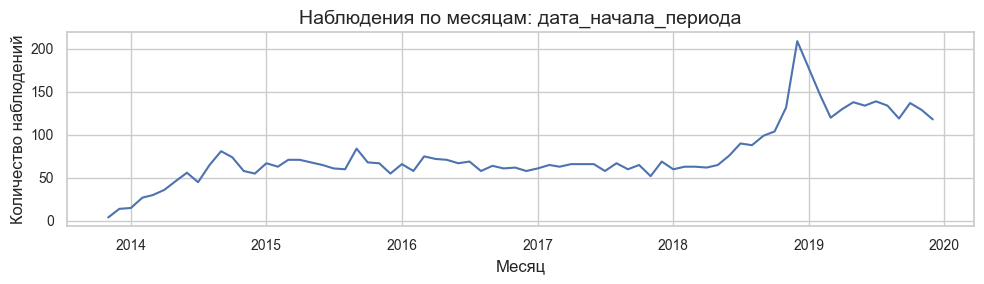

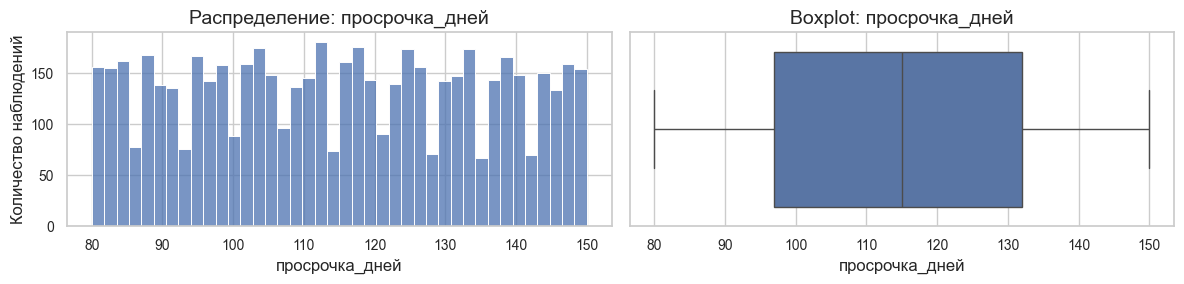


transactions


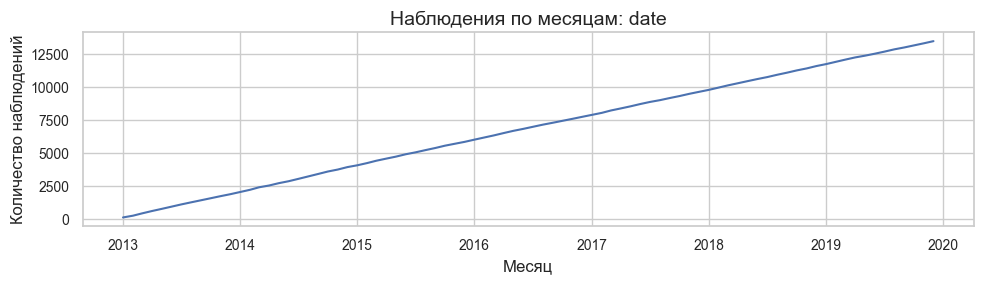

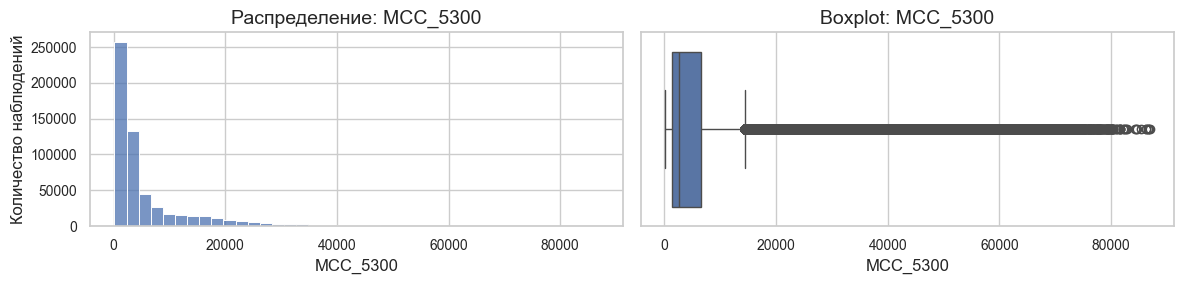

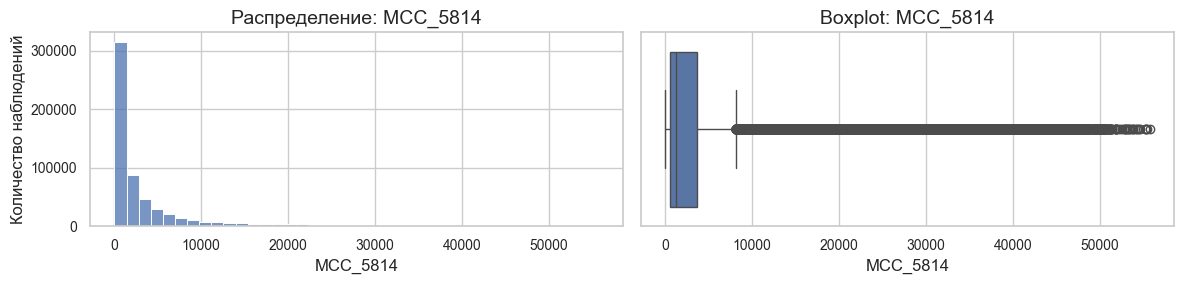

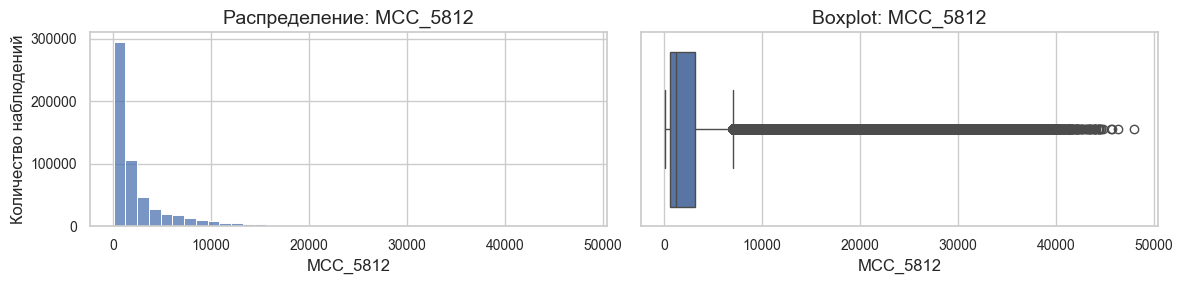

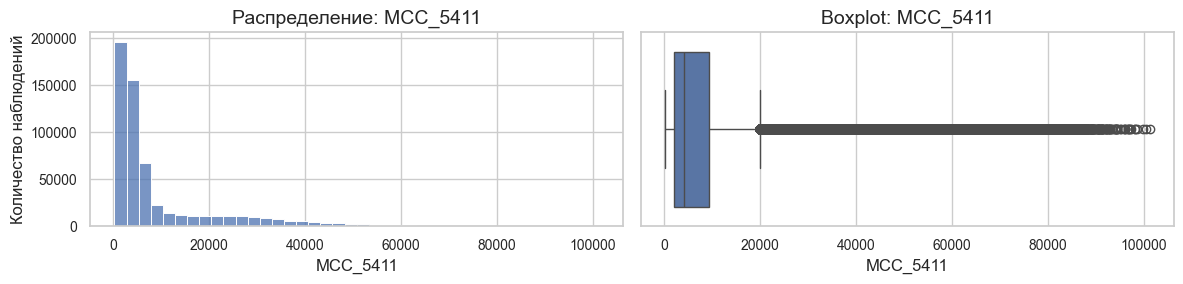

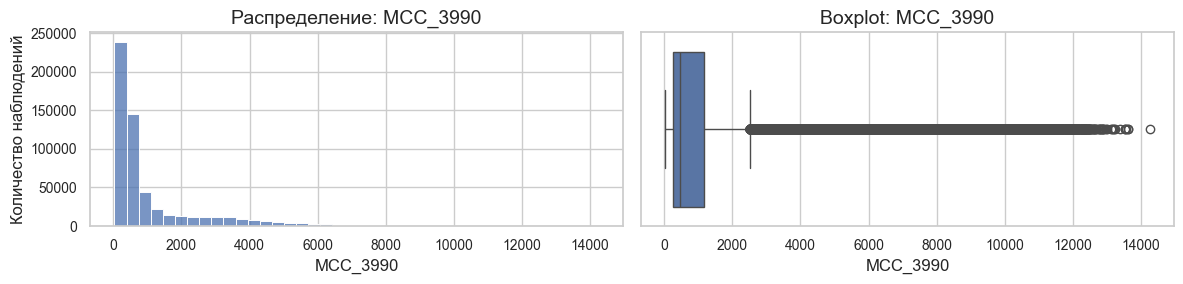

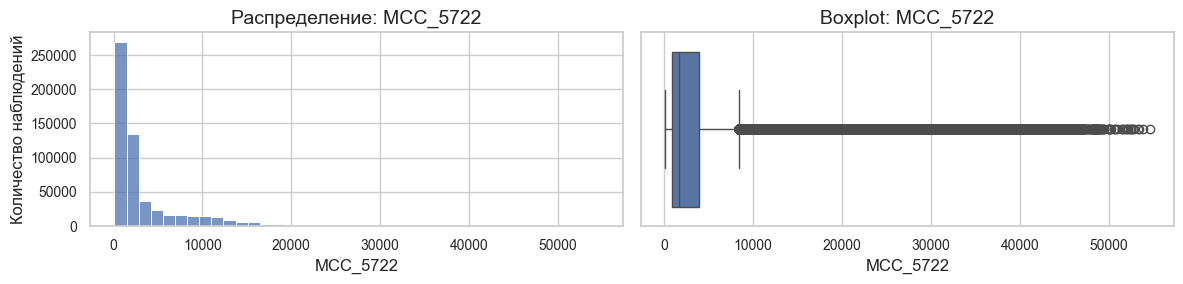

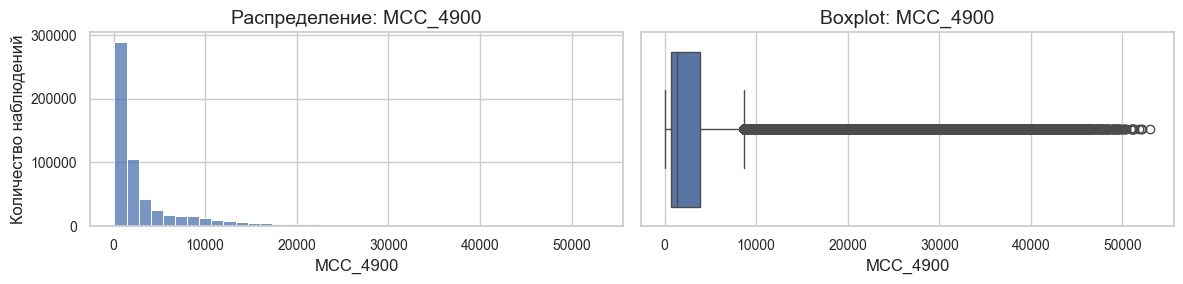

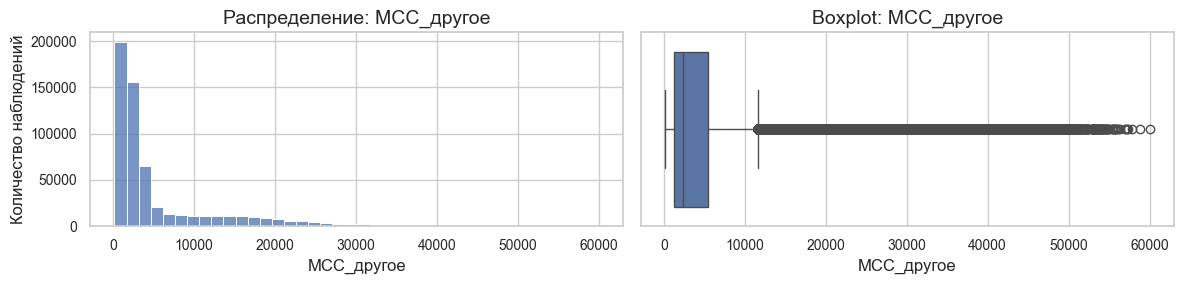


client_description


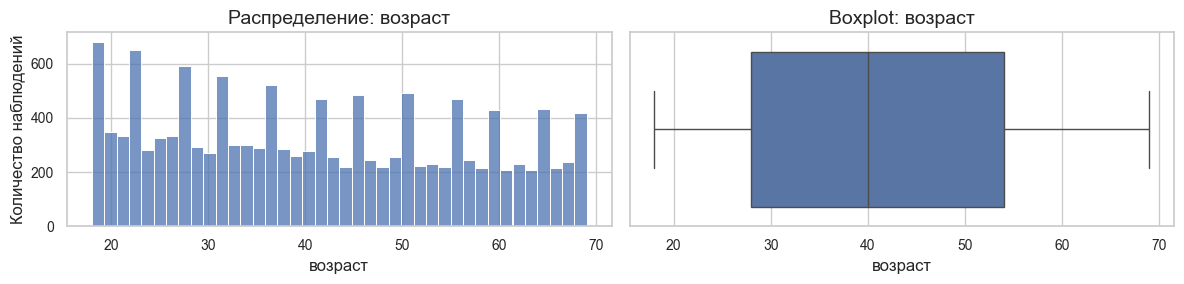

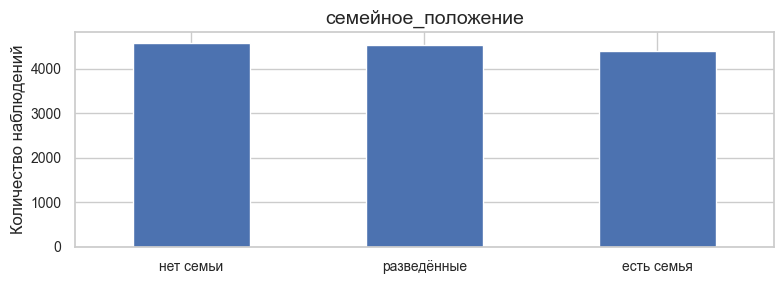

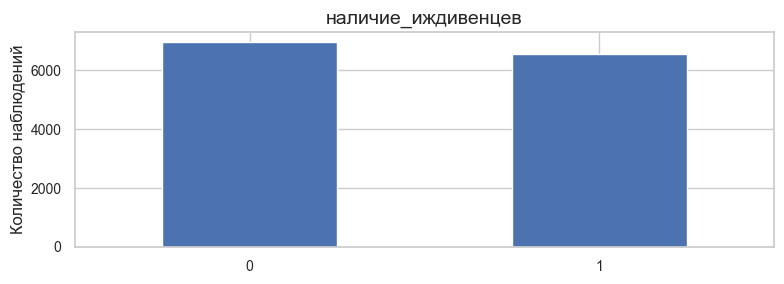

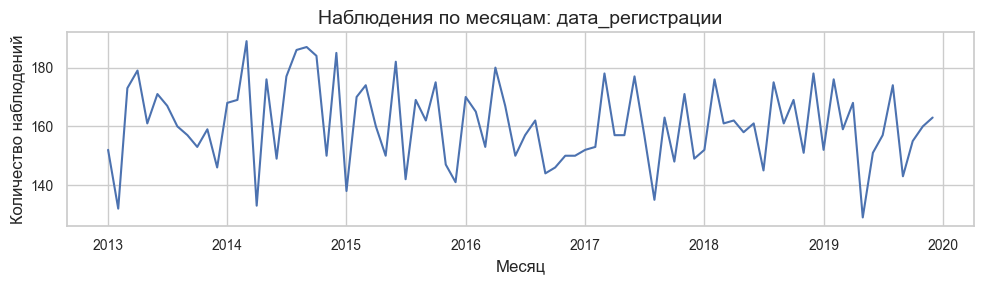


credit_description


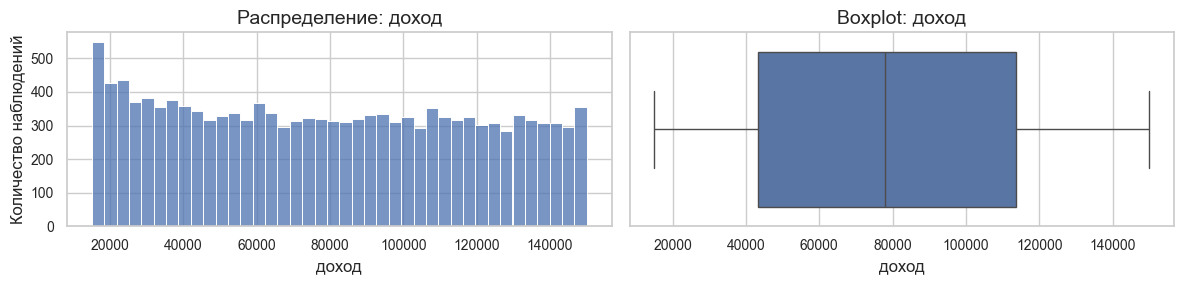

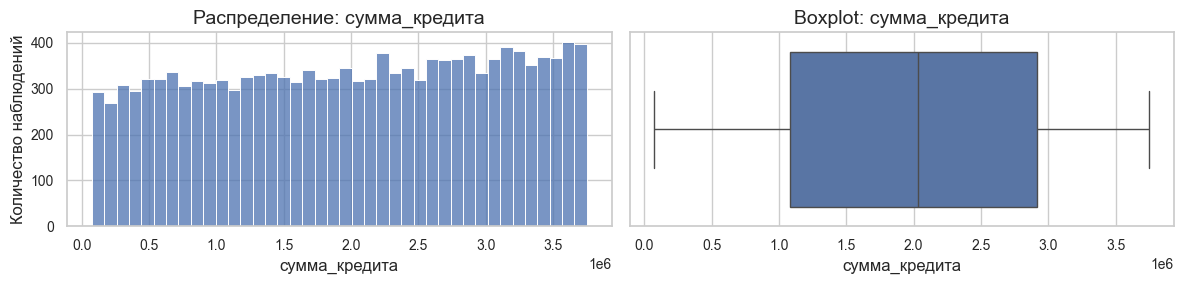


mortgage_presence


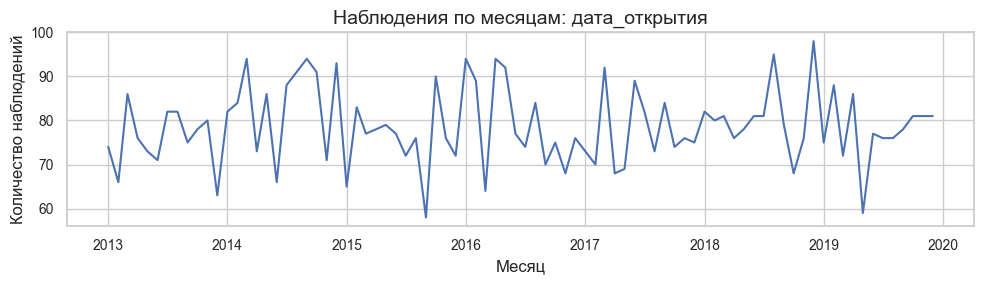

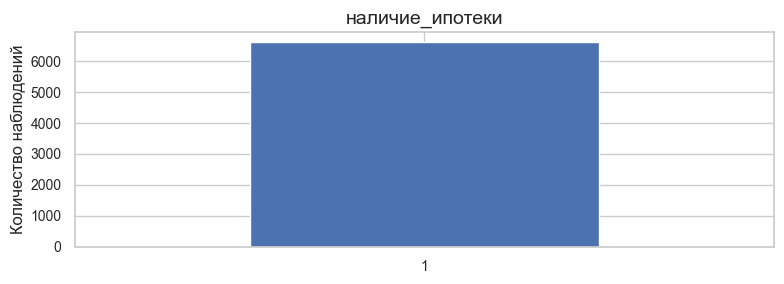


credit_rating


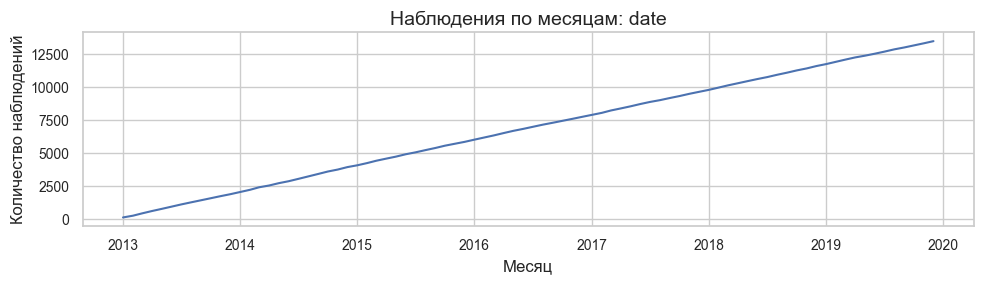

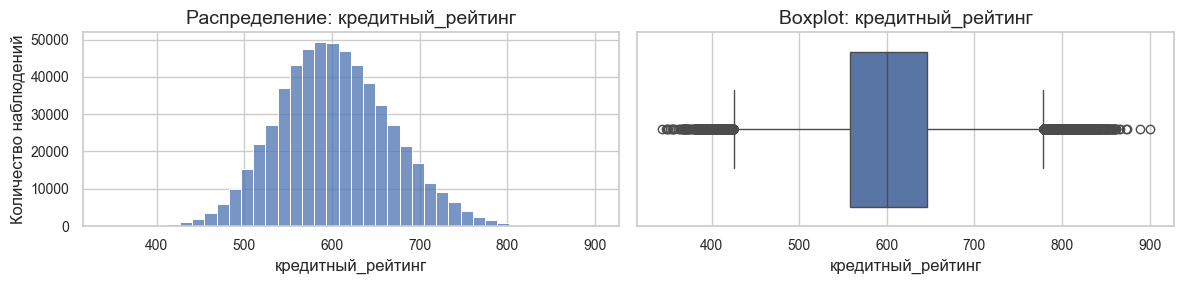


macro_data


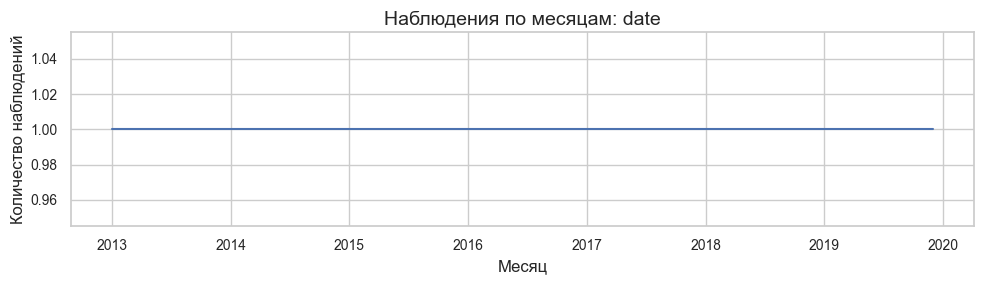

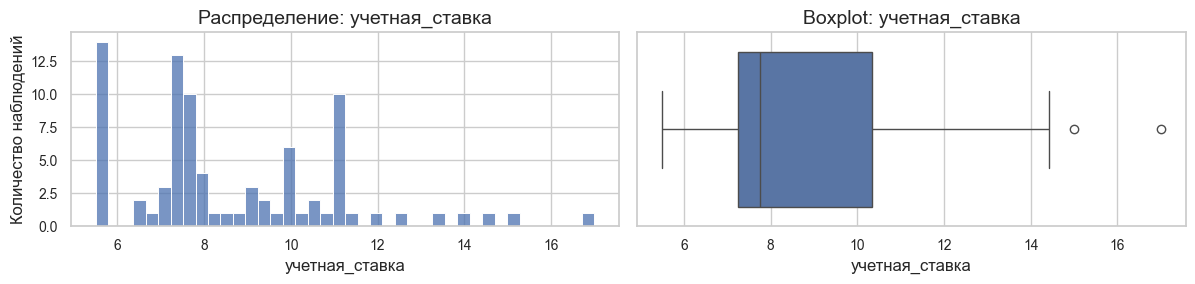

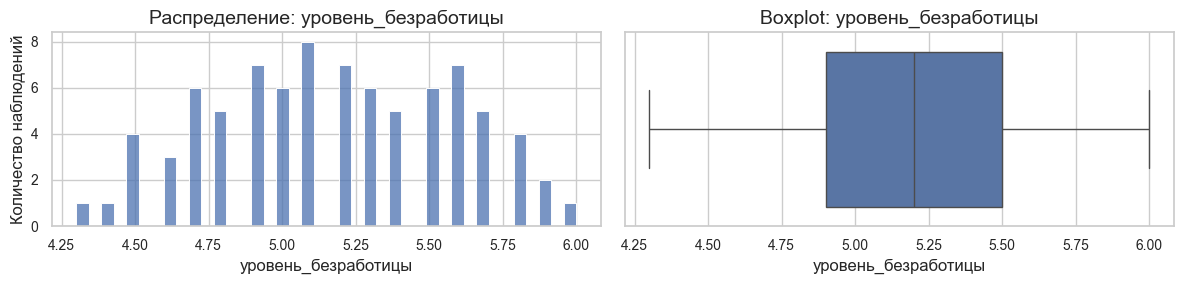

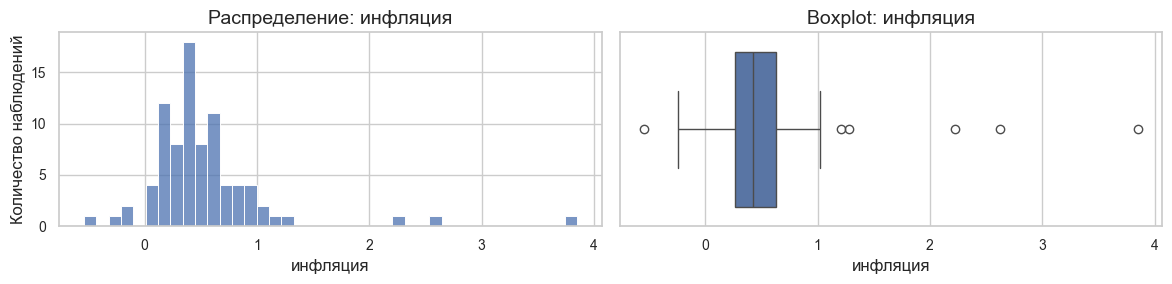


cohort_grid


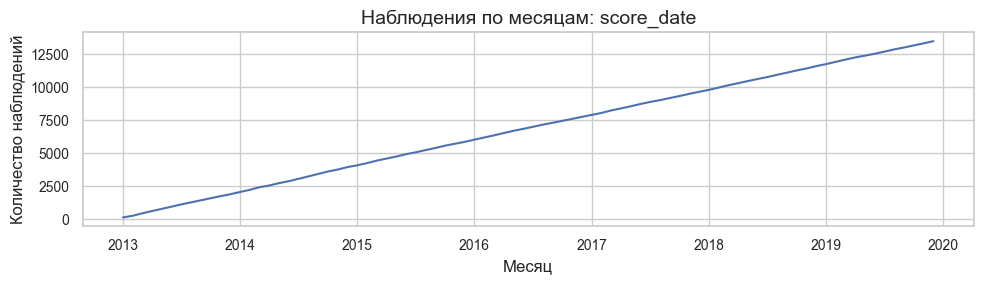

In [43]:
# Строим графики для каждой таблицы
for name, table in tables.items():
    print(f'\n{name}')
    plot_for_table(table)

#### <a id='toc1_5_2_1_'></a>[Вывод по графическому анализу](#toc0_)


Распределения расходов по MCC-категориям имеют выраженную правостороннюю асимметрию и множество высоких значений за усами boxplot. У кредитного рейтинга распределение близко к колоколообразному; крайние значения встречаются с обеих сторон. У возраста, дохода, суммы кредита и длительности просрочки выбросов по boxplot не обнаружено.

Категории семейного положения и наличия иждивенцев представлены примерно равномерно. В ипотечной таблице присутствует только значение 1. У учётной ставки и инфляции есть статистические выбросы, которые могут отражать экономические изменения.

Количество ежемесячных наблюдений растёт. В конце 2018 года заметен всплеск числа записей о начале просрочки, но без учёта размера клиентской базы его нельзя трактовать как рост доли просрочек. Оснований автоматически удалять выделенные на графиках значения нет.

### <a id='toc1_5_3_'></a>[Общий вывод по исследовательскому анализу](#toc0_)

Исследованы восемь таблиц за 2013–2019 годы. Основная сетка содержит 577 494 наблюдения «клиент — месяц» для 13 500 клиентов. Проверены типы данных, описательные статистики, пропуски и полные дубликаты; построены графики количественных, категориальных и временных данных. Во всех таблицах пропуски и полные дубликаты отсутствуют, даты преобразованы в datetime.

- **loan_payment_credit:** содержит 5 500 уникальных клиентов с длительностью просрочки 80–150 дней. Выбросов по boxplot нет. Не все записи достигают порога дефолта в 90 дней; это необходимо учитывать при формировании целевой переменной.
- **transactions:** расходы по всем MCC-категориям имеют правостороннюю асимметрию. Высокие значения могут отражать реальные различия в поведении клиентов, поэтому сохраняются.
- **client_description:** возраст клиентов составляет 18–69 лет, медиана — 40 лет. Семейные категории представлены примерно равномерно, иждивенцы есть у 48,5% клиентов. Явных аномалий на графиках не обнаружено.
- **credit_description:** медианный доход составляет около 78 тыс., сумма кредита — 2,03 млн. Значения положительные, выбросов по boxplot нет.
- **mortgage_presence:** содержит 6 609 уникальных клиентов; наличие ипотеки во всех строках равно 1. Это особенность состава таблицы. При объединении необходимо учитывать дату открытия ипотеки.
- **credit_rating:** рейтинг находится в пределах 343–900, медиана — 600. Распределение близко к колоколообразному. Крайние значения выделяются на boxplot, но их ошибочность не установлена.
- **macro_data:** содержит 84 ежемесячных наблюдения. У учётной ставки и инфляции есть статистические выбросы; у безработицы их нет. Отрицательная инфляция может отражать дефляцию.
- **cohort_grid:** сочетания ID и даты уникальны. Количество наблюдений по месяцам плавно увеличивается, что согласуется с пополнением клиентской базы.

Оснований для удаления строк, заполнения пропусков или автоматического ограничения выбросов не выявлено. Данные сохраняются для дальнейшего объединения с учётом дат и доступности информации на момент скоринга.

## <a id='toc1_6_'></a>[Объединение таблиц](#toc0_)

Соберите все источники данных о клиентах в единую таблицу наблюдений.

**Формирование целевой переменной**

1. Значение бинарной целевой переменной нужно определить для каждой строки со столбцами `ID` и `score_date` в таблице `cohort_grid`.

2. Таргет равен 1 при соблюдении двух условий:
    * Если значение в поле `просрочка_дней` больше или равно 90.
    * Если для клиента существует строка в таблице `loan_payment_credit`, где значение в поле `дата_начала_периода` попадает в интервал `[score_date, score_date + 365 дней)`.

>Важно: у клиента может быть несколько эпизодов с просрочками от 90 дней. Вам нужно взять первый по времени возникновения эпизод в таблице с просрочками.

3. После расчёта целевой переменной удалите строки, где дефолт уже произошёл к моменту скоринга, то есть `дата_начала_периода < score_date`. Это необходимо, так как для корректной работы с временной структурой важно учитывать дефолты, произошедшие в прошлом относительно даты скоринга.

**Создание итоговой таблицы**

1. В качестве признаков можно использовать только информацию о прошлом, то есть она должна быть доступна к дате скоринга. Иными словами, в каждой строке нужно присоединить данные о поведении клиента за предыдущие периоды относительно даты скоринга, иначе произойдёт утечка данных из будущего.

>К примеру, `score_date = 2024-01-15`. Тогда:
>* транзакции за декабрь 2023 г. — можем использовать;
>* транзакции за ноябрь 2023 г. — можем использовать;
>* транзакции 16 января 2024 г. — **не** можем использовать.

2. Присоедините остальные данные по клиенту, помимо указанных выше данных о макроэкономике и транзакциях клиента.

> Рекомендации:
>* Не забывайте проверять правильность каждого этапа сбора данных в единую таблицу. Это можно отслеживать на одном из клиентов.
>* При формировании таблицы следите за тем, чтобы в ней была корректно проведена работа со временем:
  >   * Отследите, не упущены ли какие-то данные из прошлого;
  >   * Проконтролируйте, верно ли рассчитана целевая переменная, которая зависит от дефолта в будущем.
>* Помните, что даты в исходных таблицах указаны на первое число месяца. Учитывайте период, который они описывают.

Сделайте выводы о получившейся таблице.

### <a id='toc1_6_1_'></a>[Формирование целевой переменной](#toc0_)

Основой служит `cohort_grid`: каждая строка соответствует клиенту на определённую дату скоринга.

Сначала отбираем эпизоды с просрочкой не менее 90 дней и определяем первый такой эпизод для каждого клиента.

Присваиваем `target = 1`, если дата первого эпизода входит в интервал `[score_date, score_date + 365 дней)`, иначе — 0. По инструкции дата эпизода, совпадающая с датой скоринга, включается в этот интервал.

После расчёта таргета исключаем наблюдения, в которых первый дефолт произошёл раньше даты скоринга.

In [44]:
# Определяем первый эпизод с просрочкой от 90 дней для каждого клиента
first_defaults = (
    loan_payment_credit.loc[
        loan_payment_credit['просрочка_дней'] >= 90,
        ['ID', 'дата_начала_периода']
    ]
    .groupby('ID', as_index=False)['дата_начала_периода']
    .min()
    .rename(columns={'дата_начала_периода': 'default_date'})
)

# Создаём основу заново из исходной сетки наблюдений
base = cohort_grid.merge(
    first_defaults, on='ID', how='left', validate='many_to_one'
)

# Формируем таргет для интервала с включённой левой и исключённой правой границей
base['target'] = (
    (base['default_date'] >= base['score_date'])
    & (base['default_date'] < base['score_date'] + pd.Timedelta(days=365))
).astype('int8')

# Исключаем наблюдения после первого дефолта
past_default = base['default_date'] < base['score_date']
print('Удалено наблюдений после дефолта:', past_default.sum())
base = base.loc[~past_default].copy()

# Проверяем уникальность наблюдений и допустимые значения таргета
assert not base.duplicated(['ID', 'score_date']).any(), 'Повторяются ID и дата'
assert base['target'].isin([0, 1]).all(), 'Некорректные значения таргета'

print('Осталось наблюдений:', len(base))
display(base['target'].value_counts().sort_index().rename('Количество'))

Удалено наблюдений после дефолта: 139115
Осталось наблюдений: 438379


target
0    389015
1     49364
Name: Количество, dtype: int64

### <a id='toc1_6_2_'></a>[Создание итоговой таблицы](#toc0_)

Признаки формируем только из информации, относящейся к моменту скоринга или предшествующим периодам.

- Характеристики клиента и кредита присоединяем по ID как статические сведения из исходных данных.
- Транзакции, кредитный рейтинг и макропоказатели присоединяем за предыдущий календарный месяц. Например, для скоринга 1 февраля используем январские показатели.
- Наличие ипотеки определяем по дате открытия: она должна быть не позднее даты скоринга. Отсутствие записи в ипотечной таблице трактуем как отсутствие ипотеки.

Для ежемесячных показателей используем окно истории в один месяц. Более ранняя история сохраняется в исходных таблицах для последующего создания признаков динамики.

Объединение выполняем через `left merge`, сохраняя все строки основы. Если исторические данные отсутствуют, оставляем пропуски.

In [45]:
# Создаём таблицу признаков без информации о дате будущего дефолта
df = base[['ID', 'score_date', 'target']].copy()
rows_before = len(df)

# Определяем предыдущий календарный месяц
df['feature_month'] = (
    df['score_date'].dt.to_period('M') - 1
).dt.to_timestamp()

# Присоединяем статические характеристики клиента и кредита
for table in [client_description, credit_description]:
    df = df.merge(table, on='ID', how='left', validate='many_to_one')
    assert len(df) == rows_before, 'При объединении изменилось число строк'

# Проверяем доступность регистрации к моменту скоринга
assert df['дата_регистрации'].notna().all(), 'Не найдена дата регистрации'
assert (df['дата_регистрации'] <= df['score_date']).all(), 'Скоринг раньше регистрации'

# Присоединяем транзакции и рейтинг за предыдущий месяц
for table in [transactions, credit_rating]:
    df = df.merge(
        table.rename(columns={'date': 'feature_month'}),
        on=['ID', 'feature_month'],
        how='left',
        validate='one_to_one'
    )
    assert len(df) == rows_before, 'При объединении изменилось число строк'

# Присоединяем макропоказатели предыдущего месяца
df = df.merge(
    macro_data.rename(columns={'date': 'feature_month'}),
    on='feature_month',
    how='left',
    validate='many_to_one'
)
assert len(df) == rows_before, 'При объединении изменилось число строк'

# Присоединяем дату открытия ипотеки
df = df.merge(
    mortgage_presence[['ID', 'дата_открытия']],
    on='ID',
    how='left',
    validate='many_to_one'
)
assert len(df) == rows_before, 'При объединении изменилось число строк'

# Рассчитываем наличие ипотеки непосредственно на дату скоринга
df['наличие_ипотеки'] = (
    df['дата_открытия'].notna()
    & (df['дата_открытия'] <= df['score_date'])
).astype('int8')

# Удаляем дату открытия, которая для некоторых наблюдений относится к будущему
df = df.drop(columns='дата_открытия')

**Проверка объединения**

Проверяем сохранение количества строк, уникальность сочетаний ID и даты, соответствие исторического месяца дате скоринга и сохранение таргета.

Для одного клиента сопоставляем присоединённые показатели с исходными значениями за предыдущий месяц. Дополнительно выводим дату первого дефолта и границу прогнозного окна для проверки целевой переменной.

In [46]:
# Проверяем структуру и временное соответствие итоговой таблицы
assert len(df) == len(base), 'Изменилось количество наблюдений'
assert not df.duplicated(['ID', 'score_date']).any(), 'Повторяются ID и дата'
assert (df['feature_month'] < df['score_date']).all(), 'Признаки не из прошлого'

# Проверяем, что при объединении таргет сохранился у соответствующих наблюдений
target_check = df[['ID', 'score_date', 'target']].merge(
    base[['ID', 'score_date', 'target']],
    on=['ID', 'score_date'],
    validate='one_to_one',
    suffixes=('_final', '_base')
)
assert target_check['target_final'].eq(target_check['target_base']).all(), 'Изменился таргет'

# Выбираем клиента с дефолтом, а при отсутствии таких — первого клиента
positive_ids = base.loc[base['target'] == 1, 'ID']
example_id = positive_ids.iloc[0] if not positive_ids.empty else base['ID'].iloc[0]

# Собираем пример с датами прогнозного окна и первого дефолта
example = (
    df.loc[
        df['ID'] == example_id,
        ['ID', 'score_date', 'feature_month', 'MCC_5411',
         'кредитный_рейтинг', 'наличие_ипотеки', 'target']
    ]
    .merge(first_defaults, on='ID', how='left', validate='many_to_one')
    .sort_values('score_date')
)
example['horizon_end'] = example['score_date'] + pd.Timedelta(days=365)

# Добавляем исходные значения за нужный месяц для прямого сравнения
for table, column in [
    (transactions, 'MCC_5411'),
    (credit_rating, 'кредитный_рейтинг')
]:
    example = example.merge(
        table[['ID', 'date', column]].rename(
            columns={'date': 'feature_month', column: f'{column}_source'}
        ),
        on=['ID', 'feature_month'],
        how='left',
        validate='one_to_one'
    )

    # Совпадающими считаем также пары отсутствующих значений
    same = (
        example[column].eq(example[f'{column}_source'])
        | (example[column].isna() & example[f'{column}_source'].isna())
    )
    assert same.all(), f'Ошибка присоединения: {column}'

# Выводим всю историю выбранного клиента для визуальной проверки
print('Проверяемый клиент:', example_id)
with pd.option_context('display.max_rows', 100, 'display.max_columns', None):
    display(example)

Проверяемый клиент: IDF55109846


,ID,score_date,feature_month,MCC_5411,кредитный_рейтинг,наличие_ипотеки,target,default_date,horizon_end,MCC_5411_source,кредитный_рейтинг_source
0,IDF55109846,2013-05-01,2013-04-01,NaN,NaN,0,0,2014-12-01,2014-05-01,NaN,NaN
1,IDF55109846,2013-06-01,2013-05-01,5711.100,692.000,0,0,2014-12-01,2014-06-01,5711.100,692.000
2,IDF55109846,2013-07-01,2013-06-01,5824.650,688.000,0,0,2014-12-01,2014-07-01,5824.650,688.000
3,IDF55109846,2013-08-01,2013-07-01,5209.510,666.000,0,0,2014-12-01,2014-08-01,5209.510,666.000
4,IDF55109846,2013-09-01,2013-08-01,5765.960,692.000,0,0,2014-12-01,2014-09-01,5765.960,692.000
5,IDF55109846,2013-10-01,2013-09-01,5632.110,688.000,0,0,2014-12-01,2014-10-01,5632.110,688.000
6,IDF55109846,2013-11-01,2013-10-01,7787.570,669.000,0,0,2014-12-01,2014-11-01,7787.570,669.000
7,IDF55109846,2013-12-01,2013-11-01,8539.470,658.000,0,0,2014-12-01,2014-12-01,8539.470,658.000
8,IDF55109846,2014-01-01,2013-12-01,8504.990,656.000,0,1,2014-12-01,2015-01-01,8504.990,656.000
9,IDF55109846,2014-02-01,2014-01-01,6842.590,655.000,0,1,2014-12-01,2015-02-01,6842.590,655.000


In [47]:
# Удаляем вспомогательный месяц объединения и сортируем итоговую таблицу
df = (
    df.drop(columns='feature_month')
    .sort_values(['score_date', 'ID'])
    .reset_index(drop=True)
)

# Показываем пропуски, возникшие после объединения
missing = df.isna().sum()
missing_summary = pd.DataFrame({
    'Количество': missing,
    'Доля, %': (missing / len(df) * 100).round(2)
})
print('Пропуски после объединения:')
display(missing_summary.loc[missing > 0])

# Выводим основные характеристики итоговой таблицы
print(f'Размер: {df.shape[0]} строк, {df.shape[1]} столбцов')
print('Уникальных клиентов:', df['ID'].nunique())
print('Полных дубликатов:', df.duplicated().sum())
display(df.head())
df.info()

Пропуски после объединения:


,Количество,"Доля, %"
MCC_5300,13500,3.080
MCC_5814,13500,3.080
MCC_5812,13500,3.080
MCC_5411,13500,3.080
MCC_3990,13500,3.080
MCC_5722,13500,3.080
MCC_4900,13500,3.080
MCC_другое,13500,3.080
кредитный_рейтинг,13500,3.080
учетная_ставка,152,0.030


Размер: 438379 строк, 22 столбцов
Уникальных клиентов: 13500
Полных дубликатов: 0


,ID,score_date,target,возраст,семейное_положение,наличие_иждивенцев,дата_регистрации,доход,сумма_кредита,MCC_5300,MCC_5814,MCC_5812,MCC_5411,MCC_3990,MCC_5722,MCC_4900,MCC_другое,кредитный_рейтинг,учетная_ставка,уровень_безработицы,инфляция,наличие_ипотеки
0,IDF54897139,2013-01-01,1,39,нет семьи,0,2013-01-01,88630,3174630,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
1,IDF54897415,2013-01-01,0,37,нет семьи,0,2013-01-01,118478,1484085,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
2,IDF54898248,2013-01-01,0,24,есть семья,1,2013-01-01,149716,2326665,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
3,IDF54898589,2013-01-01,0,31,разведённые,1,2013-01-01,84077,265020,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
4,IDF54900261,2013-01-01,0,65,есть семья,0,2013-01-01,70568,3656715,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 438379 entries, 0 to 438378
Data columns (total 22 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   ID                   438379 non-null  object        
 1   score_date           438379 non-null  datetime64[ns]
 2   target               438379 non-null  int8          
 3   возраст              438379 non-null  int64         
 4   семейное_положение   438379 non-null  object        
 5   наличие_иждивенцев   438379 non-null  int64         
 6   дата_регистрации     438379 non-null  datetime64[ns]
 7   доход                438379 non-null  int64         
 8   сумма_кредита        438379 non-null  int64         
 9   MCC_5300             424879 non-null  float64       
 10  MCC_5814             424879 non-null  float64       
 11  MCC_5812             424879 non-null  float64       
 12  MCC_5411             424879 non-null  float64       
 13  MCC_3990      

### <a id='toc1_6_3_'></a>[Вывод объединения таблиц](#toc0_)

Объединены данные о клиентах, кредитах, ипотеке, транзакциях, кредитном рейтинге и макроэкономических показателях. Итоговая таблица содержит **438 379 строк и 22 столбца**, охватывает **13 500 клиентов**. Полных дубликатов и повторов сочетания `ID` и `score_date` нет.

Целевая переменная сформирована по первому эпизоду просрочки от 90 дней в интервале `[score_date, score_date + 365 дней)`. Исключены **139 115 наблюдений** после наступления дефолта. Положительный класс составляет **49 364 наблюдения (11,26%)**, что указывает на дисбаланс классов.

Транзакции, кредитный рейтинг и макропоказатели присоединены за предыдущий календарный месяц. Наличие ипотеки определено с учётом даты её открытия. Проверка на отдельном клиенте подтвердила соответствие присоединённых значений исходным данным и корректность границ целевого интервала.

После объединения в каждом транзакционном признаке и кредитном рейтинге появилось по **13 500 пропусков (3,08%)**, что согласуется с отсутствием предыдущего месяца истории при первом наблюдении клиента. В каждом макроэкономическом показателе — **152 пропуска (0,03%)**, связанных с отсутствием данных за декабрь 2012 года. В остальных столбцах пропусков нет. Возникшие пропуски сохранены для обработки на этапе подготовки данных к моделированию.


## <a id='toc1_7_'></a>[Создание новых признаков](#toc0_)

* Добавьте в таблицу новые признаки, которые помогли бы описать поведение клиента. Создайте не менее двух новых признаков.
* Сделайте выводы о новых признаках.

Для описания поведения клиентов создадим семь новых признаков:

- **Лаг кредитного рейтинга** позволит учитывать его предыдущее значение и сопоставлять его с последним доступным рейтингом. Поскольку исходный рейтинг уже относится к предыдущему месяцу, дополнительный сдвиг на одну строку даст значение за два месяца до даты скоринга.
- **Скользящие средние расходов по MCC_3990, MCC_5814 и MCC_5812 за три месяца** сгладят разовые колебания и отразят недавний уровень расходов в выбранных категориях.
- **Накопленные максимумы расходов по MCC_4900, MCC_5722 и MCC_5411** сохранят информацию о наиболее высоких расходах клиента за доступную прошлую историю.

Такой набор объединяет отдельное прошлое значение, характеристики последних трёх месяцев и характеристики всей накопленной истории. Выбор категорий является исходной гипотезой; полезность признаков будет оценена при моделировании.

Расчёты выполняются отдельно для каждого клиента после сортировки по времени. Дополнительный сдвиг для скользящих и расширяющихся окон не требуется: расходы в итоговой таблице уже относятся к месяцу, предшествующему дате скоринга.

In [48]:
# Сортируем наблюдения каждого клиента по времени
df = df.sort_values(['ID', 'score_date'])

# Сдвигаем значения только внутри одного клиента
df['кредитный_рейтинг_lag2'] = df.groupby('ID')['кредитный_рейтинг'].shift(1)

In [49]:
m_for_rolling = ['MCC_3990', 'MCC_5814', 'MCC_5812']
m_for_expanding = ['MCC_4900', 'MCC_5722', 'MCC_5411']

# Сортируем историю каждого клиента по времени
df = df.sort_values(['ID', 'score_date'])

# Создаём короткосрочные тренды трех МСС
for m in m_for_rolling:
    df[f'{m}_rolling_3'] = df.groupby('ID')[m].rolling(window=3).mean().reset_index(level=0, drop=True)
    
# Создаём камулятивный максимум
for m in m_for_expanding:
    df[f'{m}_expanding_max'] = df.groupby('ID')[m].expanding().max().reset_index(level=0, drop=True)

In [50]:
# проверяем итоговую таблицу
df.head()

,ID,score_date,target,возраст,семейное_положение,наличие_иждивенцев,дата_регистрации,доход,сумма_кредита,MCC_5300,MCC_5814,MCC_5812,MCC_5411,MCC_3990,MCC_5722,MCC_4900,MCC_другое,кредитный_рейтинг,учетная_ставка,уровень_безработицы,инфляция,наличие_ипотеки,кредитный_рейтинг_lag2,MCC_3990_rolling_3,MCC_5814_rolling_3,MCC_5812_rolling_3,MCC_4900_expanding_max,MCC_5722_expanding_max,MCC_5411_expanding_max
436,IDF54896351,2013-03-01,0,39,нет семьи,1,2013-03-01,17633,2506575,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.500,5.800,0.560,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
893,IDF54896351,2013-04-01,0,39,нет семьи,1,2013-03-01,17633,2506575,2224.470,909.120,858.410,3911.520,428.480,1464.280,2616.170,2161.250,656.000,5.500,5.900,0.340,1,NaN,NaN,NaN,NaN,2616.170,1464.280,3911.520
1529,IDF54896351,2013-05-01,0,39,нет семьи,1,2013-03-01,17633,2506575,1986.070,1729.860,857.940,3769.950,682.430,1497.970,3011.240,2210.710,651.000,5.500,5.500,0.510,1,656.000,NaN,NaN,NaN,3011.240,1497.970,3911.520
2326,IDF54896351,2013-06-01,0,39,нет семьи,1,2013-03-01,17633,2506575,2120.910,2737.690,798.600,3436.640,720.280,1389.350,2511.640,2145.210,678.000,5.500,5.400,0.660,1,651.000,610.397,1792.223,838.317,3011.240,1497.970,3911.520
3294,IDF54896351,2013-07-01,0,39,нет семьи,1,2013-03-01,17633,2506575,2034.340,3429.410,930.140,3783.150,671.980,1447.390,1864.560,2219.610,683.000,5.500,5.300,0.420,1,678.000,691.563,2632.320,862.227,3011.240,1497.970,3911.520


### <a id='toc1_7_1_'></a>[Выводы](#toc0_)

Созданы семь новых признаков: лаг кредитного рейтинга, три скользящих средних и три накопленных максимума расходов.

Новые признаки дополняют данные за последний доступный месяц информацией о более раннем рейтинге, среднем уровне недавних расходов и исторических пиках расходов. Расчёты выполняются внутри каждого клиента и используют только информацию за прошлые периоды.

В начале истории возникают пропуски: для лага необходимо предыдущее наблюдение с известным рейтингом, для скользящего среднего — три непустых значения в окне, для накопленного максимума — хотя бы одно известное значение. Эти пропуски сохранены.

Требование создать не менее двух новых признаков выполнено. Их вклад в качество прогноза предстоит оценить на этапе моделирования.

## <a id='toc1_8_'></a>[Анализ итоговой таблицы](#toc0_)

* Проведите краткий анализ получившейся итоговой таблицы.
* Сделайте вывод о данных для моделирования.
* Проверьте целевую переменную на предмет дисбаланса классов. Сделайте выводы.

### <a id='toc1_8_1_'></a>[Анализ получившейся таблицы](#toc0_)

In [51]:
# Проверяем размер, охват клиентов и временной период
print(f'Размер таблицы: {df.shape[0]} строк, {df.shape[1]} столбцов')
print(f'Уникальных клиентов: {df["ID"].nunique()}')
print(f'Период: {df["score_date"].min():%Y-%m-%d} — {df["score_date"].max():%Y-%m-%d}')
print(f'Полных дубликатов: {df.duplicated().sum()}')
print(f'Повторов ID и score_date: {df.duplicated(["ID", "score_date"]).sum()}')

# Показываем типы данных, пропуски и количество уникальных значений
summary = pd.DataFrame({
    'Тип': df.dtypes.astype(str),
    'Пропуски': df.isna().sum(),
    'Пропуски, %': df.isna().mean().mul(100).round(2),
    'Уникальных значений': df.nunique()
})
display(summary)

Размер таблицы: 438379 строк, 29 столбцов
Уникальных клиентов: 13500
Период: 2013-01-01 — 2019-12-01
Полных дубликатов: 0
Повторов ID и score_date: 0


,Тип,Пропуски,"Пропуски, %",Уникальных значений
ID,object,0,0.000,13500
score_date,datetime64[ns],0,0.000,84
target,int8,0,0.000,2
возраст,int64,0,0.000,52
семейное_положение,object,0,0.000,3
наличие_иждивенцев,int64,0,0.000,2
дата_регистрации,datetime64[ns],0,0.000,84
доход,int64,0,0.000,12801
сумма_кредита,int64,0,0.000,13140
MCC_5300,float64,13500,3.080,352362


Итоговая таблица содержит **438 379 строк и 29 столбцов** по **13 500 клиентам** за январь 2013 — декабрь 2019 года. Полных дубликатов и повторов сочетания `ID` и `score_date` нет. Доля пропусков составляет 3,08% в расходах, рейтинге и накопленных максимумах, 6,12% в лаге рейтинга и 9,11% в скользящих средних. Это согласуется с необходимой глубиной истории для расчёта признаков. В макропоказателях пропущено 0,03% значений; остальные столбцы заполнены полностью.

### <a id='toc1_8_2_'></a>[Характеристики признаков](#toc0_)

In [52]:
# Описываем числовые признаки без целевой переменной
numeric_cols = df.select_dtypes(include='number').columns.drop('target')
display(df[numeric_cols].describe().T.round(2))

# Проверяем бесконечные значения в числовых признаках
infinite_counts = df[numeric_cols].isin([float('inf'), float('-inf')]).sum()
print('Бесконечных значений:', infinite_counts.sum())

# Показываем распределение категориальных признаков, исключая ID
category_cols = df.select_dtypes(include=['object', 'category']).columns.drop('ID')
for col in category_cols:
    print(f'\n{col}')
    display(pd.DataFrame({
        'Количество': df[col].value_counts(dropna=False),
        'Доля, %': df[col].value_counts(dropna=False, normalize=True).mul(100).round(2)
    }))

,count,mean,std,min,25%,50%,75%,max
возраст,438379.000,42.990,15.160,18.000,30.000,43.000,56.000,69.000
наличие_иждивенцев,438379.000,0.500,0.500,0.000,0.000,0.000,1.000,1.000
доход,438379.000,80757.450,39664.120,15010.000,45665.000,80473.000,115066.000,149988.000
сумма_кредита,438379.000,1934286.440,1064196.650,75000.000,1013505.000,1939365.000,2851950.000,3749400.000
MCC_5300,424879.000,7633.280,9849.520,170.010,1662.130,3304.710,10095.430,86939.400
MCC_5814,424879.000,4369.690,6407.650,62.180,704.870,1682.250,5145.320,55720.690
MCC_5812,424879.000,3699.370,5082.610,69.940,741.860,1553.080,4623.540,47969.570
MCC_5411,424879.000,11476.610,13611.920,297.280,2633.300,5039.520,16440.900,101301.950
MCC_3990,424879.000,1401.640,1727.390,31.900,300.510,589.940,1976.780,14261.490
MCC_5722,424879.000,4450.310,5566.840,108.400,1008.460,1955.690,6126.550,54630.190


Бесконечных значений: 0

семейное_положение


,Количество,"Доля, %"
семейное_положение,,
нет семьи,146799,33.490
есть семья,146291,33.370
разведённые,145289,33.140


Расходы по MCC характеризуются большим разбросом: средние заметно превышают медианы, что указывает на правостороннюю асимметрию. Такая форма распределения соответствует типичному для покупательского поведения паттерну, описываемому **Negative Binomial Distribution (NBD)**: большинство клиентов являются редкими (light buyers), тогда как небольшая доля клиентов совершает значительно больше покупок и формирует длинный правый хвост распределения. Медиана кредитного рейтинга составляет 609 баллов, дохода — 80 473, суммы кредита — 1 939 365. Категории семейного положения представлены почти равномерно — примерно по 33% наблюдений. Бесконечных значений нет. Скользящие средние сглаживают колебания расходов, а накопленные максимумы отражают их исторические пики.

### <a id='toc1_8_3_'></a>[Баланс целевой переменной](#toc0_)

Значения target: [0 1]
Пропусков в target: 0


,Количество,"Доля, %"
target,,
0,389015,88.740
1,49364,11.260


Соотношение большего класса к меньшему: 7.88:1


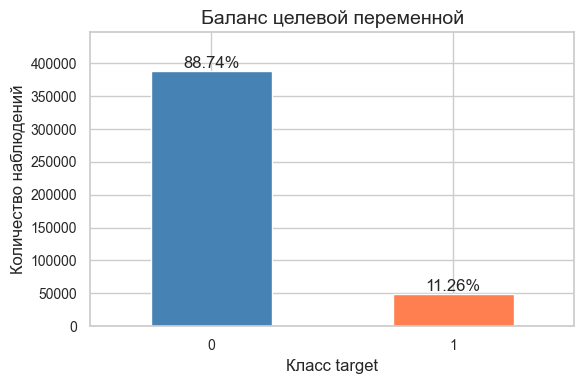

In [53]:
# Проверяем значения и пропуски целевой переменной
print('Значения target:', df['target'].unique())
print('Пропусков в target:', df['target'].isna().sum())

# Рассчитываем количество и долю наблюдений каждого класса
class_counts = df['target'].value_counts().reindex([0, 1], fill_value=0)
balance = pd.DataFrame({
    'Количество': class_counts,
    'Доля, %': class_counts.div(len(df)).mul(100).round(2)
})
balance.index.name = 'target'
display(balance)

# Оцениваем соотношение классов
if class_counts.min() > 0:
    print(f'Соотношение большего класса к меньшему: {class_counts.max() / class_counts.min():.2f}:1')
else:
    print('Один из классов отсутствует.')

# Визуализируем распределение классов
ax = balance['Количество'].plot.bar(
    figsize=(6, 4), color=['steelblue', 'coral'], rot=0
)
ax.set_title('Баланс целевой переменной')
ax.set_xlabel('Класс target')
ax.set_ylabel('Количество наблюдений')

# Подписываем доли классов над столбцами
for i, (count, share) in enumerate(zip(balance['Количество'], balance['Доля, %'])):
    ax.text(i, count, f'{share:.2f}%', ha='center', va='bottom')

ax.set_ylim(0, class_counts.max() * 1.15)
plt.tight_layout()
plt.show()

Целевая переменная содержит только значения 0 и 1, пропусков нет. Класс 0 представлен **389 015 наблюдениями (88,74%)**, класс 1 — **49 364 наблюдениями (11,26%)**. Соотношение классов составляет **7,88:1**, поэтому дисбаланс необходимо учитывать при обучении и оценке моделей. Одна accuracy недостаточна: постоянный прогноз класса 0 уже обеспечит 88,74%, не выявив ни одного положительного наблюдения.  
  
При построении моделей стоит применить один из методов борьбы с дисбалансом целевой переменной. Так как значения более 400 000 - скорее всего подойдет комбинированная стратегия.

### <a id='toc1_8_4_'></a>[Общие выводы](#toc0_)

Сформирована итоговая таблица из **438 379 наблюдений и 29 столбцов**, объединяющая клиентские и кредитные характеристики, расходы, рейтинг, ипотеку и макроэкономические показатели. Семь новых признаков дополняют данные информацией о предыдущем рейтинге, среднем уровне расходов за три месяца и накопленных максимумах. Единица наблюдения — клиент на определённую дату скоринга; показатели описательной статистики рассчитаны по таким наблюдениям, а не по уникальным клиентам.

Полных дубликатов, повторов ключа `ID` и `score_date`, бесконечных значений и пропусков в целевой переменной не обнаружено. Пропуски в признаках связаны с отсутствием доступной прошлой истории и достигают 9,11% в скользящих средних. При подготовке к обучению потребуется выбрать способ их обработки с учётом используемой модели, а также закодировать семейное положение. Параметры заполнения пропусков и других обучаемых преобразований следует определять только на обучающей выборке.

Расходы имеют выраженную правостороннюю асимметрию, а признаки различаются по масштабу. Эти особенности нужно учитывать при выборе предобработки; сами по себе большие значения не являются основанием для удаления наблюдений. `ID` следует использовать как идентификатор, а даты — для временного разделения данных и, при необходимости, создания осмысленных признаков.

Положительный класс составляет **11,26%**, поэтому качество моделей необходимо оценивать с учётом дисбаланса и способности обнаруживать будущий дефолт. Данные подготовлены к следующему этапу — формированию выборок и настройке предобработки для моделирования.

## <a id='toc1_9_'></a>[Моделирование](#toc0_)

### <a id='toc1_9_1_'></a>[Базовые модели](#toc0_)

1. Подготовьте обучающую, калибровочную и тестовую выборки. Разбейте обучающую на три фолда для последующего использования кросс-валидации. Для оценки качества и калибровки используйте размер выборки, равный 12 месяцам.


2. При необходимости проведите категоризацию данных, применив нужный Encoder и использовав пайплайн.

3. Обучите базовые модели с кросс-валидацией по трём фолдам:
    * Две базовые модели — логистическую регрессию и случайный лес — без балансировки классов в целевой переменной.
    * Логистическую регрессию и случайный лес с балансировкой классов. Выберите метод балансировки самостоятельно. Обязательно примените хотя бы один метод. Можно попробовать несколько и выбрать лучший.
    * Сделайте выводы о работе всех четырёх моделей.

4. Случайный лес с настройками по умолчанию легко переобучается, потому что запоминает обучающую выборку, из-за чего модель может терять в качестве на новых данных. Логистическая регрессия же сразу готова к работе за счёт встроенной L2-регуляризации, которая автоматически контролирует сложность модели.

   Чтобы исправить проблемы модели Random Forest, вам нужно подобрать для неё гиперпараметры с помощью  Optuna. Количество гиперпараметров должно быть не менее трёх. Для оптимизации используйте метрику missed defaults rate.

5. Сравните все полученные модели.

6. Для оценки моделей используйте метрики:
   * accuracy или ROC-AUC,
   * approval rate,
   * default rate,
   * missed defaults rate.

7. Сделайте вывод о работе, проделанной в этом разделе.

### <a id='toc1_9_2_'></a>[Разделение на обучающую, калибровочную и тестовую выборку](#toc0_)

In [54]:
# принимаем дату за индекс и сортируем по дате
df_sorted = df.set_index('score_date').sort_index()

# Определяем сплит-поинты для калибровочной и тестовой даты
test_split_point = pd.Timestamp('2019-01-01')
cal_split_point = pd.Timestamp('2018-01-01')


train_data = df_sorted.iloc[df_sorted.index < cal_split_point].copy()
cal_data = df_sorted.iloc[
    (df_sorted.index >= cal_split_point) & 
    (df_sorted.index < test_split_point)].copy()
test_data = df_sorted.iloc[df_sorted.index >= test_split_point].copy()

print("Отсортированный ряд:\n", df_sorted.index[:5])
print("Обучающая:\n", train_data.index[:5])
print("Калибровочная:\n", cal_data.index[:5])
print("Тестовая:\n", test_data.index[:5])


Отсортированный ряд:
 DatetimeIndex(['2013-01-01', '2013-01-01', '2013-01-01', '2013-01-01', '2013-01-01'], dtype='datetime64[ns]', name='score_date', freq=None)
Обучающая:
 DatetimeIndex(['2013-01-01', '2013-01-01', '2013-01-01', '2013-01-01', '2013-01-01'], dtype='datetime64[ns]', name='score_date', freq=None)
Калибровочная:
 DatetimeIndex(['2018-01-01', '2018-01-01', '2018-01-01', '2018-01-01', '2018-01-01'], dtype='datetime64[ns]', name='score_date', freq=None)
Тестовая:
 DatetimeIndex(['2019-01-01', '2019-01-01', '2019-01-01', '2019-01-01', '2019-01-01'], dtype='datetime64[ns]', name='score_date', freq=None)


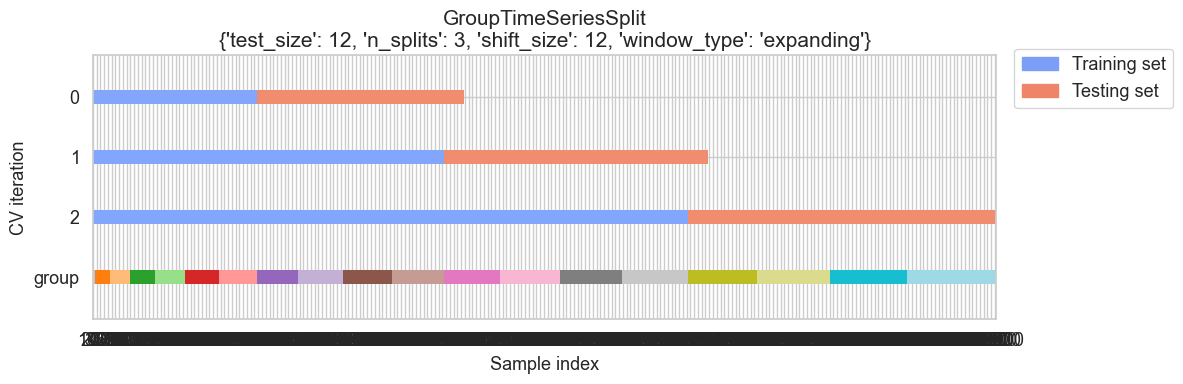

Train indices: [    0     1     2 ... 46152 46153 46154]
Test indices: [46155 46156 46157 ... 96135 96136 96137]
Train length: 46155
Test length: 49983
Train groups: [ 0  0  0 ... 23 23 23]
Test groups: [24 24 24 ... 35 35 35]
Train group size: 24
Test group size: 12
Train group months: ['2013-01-01T00:00:00.000000000' '2013-01-01T00:00:00.000000000'
 '2013-01-01T00:00:00.000000000' ... '2014-12-01T00:00:00.000000000'
 '2014-12-01T00:00:00.000000000' '2014-12-01T00:00:00.000000000']
Test group months: ['2015-01-01T00:00:00.000000000' '2015-01-01T00:00:00.000000000'
 '2015-01-01T00:00:00.000000000' ... '2015-12-01T00:00:00.000000000'
 '2015-12-01T00:00:00.000000000' '2015-12-01T00:00:00.000000000']

Train indices: [    0     1     2 ... 96135 96136 96137]
Test indices: [ 96138  96139  96140 ... 160950 160951 160952]
Train length: 96138
Test length: 64815
Train groups: [ 0  0  0 ... 35 35 35]
Test groups: [36 36 36 ... 47 47 47]
Train group size: 36
Test group size: 12
Train group months

In [55]:
# создаем валидационные фолды через GroupTSS

# разделяем Х и у

X_train_val = train_data.drop(columns=['ID', 'target'])
y_train_val = train_data['target']

# Кодируем месяцы числами: одинаковый год-месяц получает одинаковый номер
groups = pd.factorize(train_data.index.to_period('M'))[0]

cv_args = {
    "test_size":12,
    "n_splits":3,
    "shift_size":12,
    "window_type": "expanding"
}

# Инициируем gtss

gtss = GroupTimeSeriesSplit(**cv_args)


# Визуализация разбиений
plot_splits(X_train_val, y_train_val, groups=groups, **cv_args)

# Детальная информация по каждому разбиению
print_split_info(X_train_val, y_train_val, groups=groups, **cv_args)

### <a id='toc1_9_3_'></a>[Категоризация данных](#toc0_)

In [56]:
# Количественные признаки: заполнение пропусков и масштабирование
num_columns = [
    'возраст', 'доход', 'сумма_кредита',
    'MCC_5300', 'MCC_5814', 'MCC_5812', 'MCC_5411',
    'MCC_3990', 'MCC_5722', 'MCC_4900', 'MCC_другое',
    'кредитный_рейтинг', 'учетная_ставка', 'уровень_безработицы', 'инфляция',
    'кредитный_рейтинг_lag2',
    'MCC_3990_rolling_3', 'MCC_5814_rolling_3', 'MCC_5812_rolling_3',
    'MCC_4900_expanding_max', 'MCC_5722_expanding_max', 'MCC_5411_expanding_max'
]

# Категориальный признак: кодирование OneHotEncoder
cat_columns = ['семейное_положение']

# Бинарные признаки: передаём без изменений
bi_columns = ['наличие_иждивенцев', 'наличие_ипотеки']

In [57]:
# Последовательно заполняем пропуски и масштабируем числовые признаки
num_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaling', StandardScaler())
])

# Кодируем категории; неизвестные категории не вызывают ошибку
cat_transformer = OneHotEncoder(handle_unknown='ignore')


# Объединяем обработку разных типов признаков
preprocessor = ColumnTransformer([
    ('num', num_transformer, num_columns),
    ('cat', cat_transformer, cat_columns),
    ('bi', 'passthrough', bi_columns)
], remainder='drop')  # Исключаем неуказанные столбцы, включая дату регистрации


### <a id='toc1_9_4_'></a>[Обучение базовых моделей](#toc0_)

Дописать что смоте не используется, потому что есть кат данные, а они не очень дружат


In [62]:
# создание пайплайнов для бэйс_моделей

pipelines = {
    # модели без балансировки классов
    'base_log_reg':ImbPipeline([
        ('preprocessor', preprocessor),
        ('model', LogisticRegression())
    ]),
    
    'base_random_forest':ImbPipeline([
        ('preprocessor', preprocessor),
        ('model', RandomForestClassifier(random_state=RANDOM_STATE))
    ]),
    
    # модели с оверсемплингом
    'log_reg_oversampling':ImbPipeline([
        ('preprocessor', preprocessor),
        ('sampler', RandomOverSampler(random_state=RANDOM_STATE)),
        ('model', LogisticRegression())
    ]),
    
    'random_forest_oversampling':ImbPipeline([
        ('preprocessor', preprocessor),
        ('sampler', RandomOverSampler(random_state=RANDOM_STATE)),
        ('model', RandomForestClassifier(random_state=RANDOM_STATE))
    ]),
    
    # модели с СМОТ
    'log_reg_smote':ImbPipeline([
        ('preprocessor', preprocessor),
        ('sampler', SMOTE(random_state=RANDOM_STATE)),
        ('model', LogisticRegression())
    ]),
    
    'random_forest_smote':ImbPipeline([
        ('preprocessor', preprocessor),
        ('sampler', SMOTE(random_state=RANDOM_STATE)),
        ('model', RandomForestClassifier(random_state=RANDOM_STATE))
    ]),
    
    # модели с андерсемплингом
    'log_reg_undersampling':ImbPipeline([
        ('preprocessor', preprocessor),
        ('sampler', RandomUnderSampler(random_state=RANDOM_STATE)),
        ('model', LogisticRegression())
    ]),
        
    'random_forest_undersampling':ImbPipeline([
        ('preprocessor', preprocessor),
        ('sampler', RandomUnderSampler(random_state=RANDOM_STATE)),
        ('model', RandomForestClassifier(random_state=RANDOM_STATE))
    ]),
    
    # модели с комбинированным подходом
    'log_reg_combined':ImbPipeline([
        ('preprocessor', preprocessor),
        ('over', RandomOverSampler(random_state=RANDOM_STATE, sampling_strategy=0.5)),
        ('under', RandomUnderSampler(random_state=RANDOM_STATE, sampling_strategy=1.0)),
        ('model', LogisticRegression())
    ]),
        
    'random_forest_combined':ImbPipeline([
        ('preprocessor', preprocessor),
        ('over', RandomOverSampler(random_state=RANDOM_STATE, sampling_strategy=0.5)),
        ('under', RandomUnderSampler(random_state=RANDOM_STATE, sampling_strategy=1.0)),
        ('model', RandomForestClassifier(random_state=RANDOM_STATE))    
    ]),
}

In [63]:
cv_results = {}

scoring = {
    'roc_auc': 'roc_auc',
    'accuracy': 'accuracy'
}

for name, pipeline in pipelines.items():
    scores = cross_validate(
        estimator=pipeline,
        X=X_train_val,
        y=y_train_val,
        cv=gtss,
        groups=groups,
        scoring=scoring,
        return_train_score=True,
        n_jobs=-1
    )
    
    cv_results[name] = scores

In [65]:
df_results = pd.DataFrame({
    name: {
        'roc_auc_mean': results['test_roc_auc'].mean(),
        'accuracy_mean': results['test_accuracy'].mean()
    }
    for name, results in cv_results.items()
}).T

In [66]:
df_results

,roc_auc_mean,accuracy_mean
base_log_reg,0.853,0.869
base_random_forest,0.894,0.881
log_reg_oversampling,0.855,0.781
random_forest_oversampling,0.898,0.881
log_reg_smote,0.854,0.791
random_forest_smote,0.895,0.869
log_reg_undersampling,0.855,0.776
random_forest_undersampling,0.888,0.817
log_reg_combined,0.855,0.781
random_forest_combined,0.893,0.861


Лучшие модели по среднему ROC-AUC: случайный лес с оверсемплингом (0,898), с SMOTE (0,895) и без балансировки (0,894). По accuracy лидируют лес с оверсемплингом и базовый лес — по 0,881; у SMOTE — 0,869.

Предположительно, лес лучше логистической регрессии улавливает нелинейные зависимости и взаимодействия признаков. Оверсемплинг усиливает внимание к редкому классу дефолтов и здесь даёт лучший ROC-AUC без снижения accuracy. SMOTE также помогает учитывать редкий класс, но синтетические наблюдения могли привести к большему числу ошибок при стандартном пороге.

### <a id='toc1_9_5_'></a>[Оптуна для моделей леса](#toc0_)

In [ ]:
def objective(trial, pipeline):
    # Подбираем четыре гиперпараметра случайного леса
     # Подбираем три гиперпараметра — сохраняем требование задания
    params = {
        'model__n_estimators': trial.suggest_int(
            'n_estimators', 75, 100
        ),
        'model__max_depth': trial.suggest_int(
            'max_depth', 10, 15
        ),
        # Рассматриваем ограниченное число признаков при каждом разбиении
        'model__max_features': trial.suggest_categorical(
            'max_features', ['sqrt', 'log2']
        )
    }

    # Создаём копию готового пайплайна и задаём параметры леса
    model = clone(pipeline).set_params(**params)

    # Оцениваем recall на трёх временных фолдах
    # Предобработка и балансировка обучаются внутри каждого фолда
    scores = cross_val_score(
        estimator=model,
        X=X_train_val,
        y=y_train_val,
        cv=gtss,
        groups=groups,
        scoring='recall',
        n_jobs=-1,
        error_score='raise'
    )

    # Возвращаем среднюю долю пропущенных дефолтов: чем меньше, тем лучше
    return 1 - scores.mean()

Первоначально планировалось подобрать гиперпараметры с помощью Optuna для всех вариантов случайного леса. Однако такой подход оказался слишком затратным по времени, поэтому было принято решение оптимизировать лес с оверсемплингом, показавший лучший средний ROC-AUC на кросс-валидации среди базовых моделей.

In [84]:
try:
    # Загружаем готовые результаты и пропускаем подбор, если файл существует
    checkpoint = joblib.load('optuna_checkpoint.joblib')
    studies = checkpoint['studies']
    tuned_pipelines = checkpoint['tuned_pipelines']
    optuna_results = checkpoint['optuna_results']

    print('Результаты загружены из файла. Подбор пропущен.')

except FileNotFoundError:
    # Если файла нет, запускаем подбор параметров
    studies = {}
    tuned_pipelines = {}

    # Подбираем параметры только леса с оверсемплингом
    for name in ['random_forest_oversampling']:
        pipeline = pipelines[name]

        # Создаём исследование для минимизации доли пропущенных дефолтов
        study = optuna.create_study(
            direction='minimize',
            sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE)
        )

        # Закрепляем текущий пайплайн за функцией оптимизации
        objective_model = partial(objective, pipeline=pipeline)

        # Проверяем 10 наборов параметров
        study.optimize(objective_model, n_trials=10)
        studies[name] = study

        # Добавляем префикс шага модели к названиям параметров
        best_params = {
            f'model__{param}': value
            for param, value in study.best_params.items()
        }

        # Сохраняем настроенный пайплайн; на всей выборке пока не обучаем
        tuned_pipelines[name] = clone(pipeline).set_params(**best_params)

    # Собираем таблицу результатов перед сохранением
    optuna_results = pd.DataFrame([
        {
            'model': name,
            'missed_defaults_rate': study.best_value,
            'best_params': study.best_params
        }
        for name, study in studies.items()
    ]).sort_values('missed_defaults_rate').reset_index(drop=True)

    # Сохраняем результаты для следующих запусков
    joblib.dump(
        {
            'studies': studies,
            'tuned_pipelines': tuned_pipelines,
            'optuna_results': optuna_results
        },
        'optuna_checkpoint.joblib'
    )

    print('Подбор завершён. Результаты сохранены.')

# Показываем результаты после загрузки или нового подбора
display(optuna_results)

Результаты загружены из файла. Подбор пропущен.


,model,missed_defaults_rate,best_params
0,random_forest_oversampling,0.168,"{'n_estimators': 79, 'max_depth': 10, 'max_features': 'log2'}"


In [82]:
# Сравниваем лучшие результаты подбора по доле пропущенных дефолтов
optuna_results = pd.DataFrame([
    {
        'model': name,
        'missed_defaults_rate': study.best_value,
        'best_params': study.best_params
    }
    for name, study in studies.items()
]).sort_values('missed_defaults_rate').reset_index(drop=True)

display(optuna_results)

,model,missed_defaults_rate,best_params
0,random_forest_oversampling,0.168,"{'n_estimators': 79, 'max_depth': 10, 'max_features': 'log2'}"


In [ ]:
# для удобства 

# Сохраняем результаты подбора и настроенные пайплайны
joblib.dump(
    {
        'studies': studies,
        'tuned_pipelines': tuned_pipelines,
        'optuna_results': optuna_results
    },
    'optuna_checkpoint.joblib'
)

['optuna_checkpoint.joblib']

In [ ]:
# дляудобства


# Восстанавливаем результаты без повторного запуска Optuna
checkpoint = joblib.load('optuna_checkpoint.joblib')

studies = checkpoint['studies']
tuned_pipelines = checkpoint['tuned_pipelines']
optuna_results = checkpoint['optuna_results']

display(optuna_results)

,model,missed_defaults_rate,best_params
0,random_forest_oversampling,0.168,"{'n_estimators': 79, 'max_depth': 10, 'max_features': 'log2'}"


### <a id='toc1_9_6_'></a>[Сравнение всех моделей](#toc0_)

Все базовые модели и случайный лес после Optuna сравниваются на одинаковых трёх временных фолдах. Рассчитываются средние значения ROC-AUC, accuracy и бизнес-метрик:

- Approval rate — доля одобренных наблюдений: модель предсказывает отсутствие дефолта.
- Default rate — доля фактических дефолтов среди одобренных наблюдений.
- Missed defaults rate — доля пропущенных дефолтов среди всех фактических дефолтов.

Класс 1 означает дефолт, класс 0 — отсутствие дефолта. Для сравнения используются стандартные предсказания классов; подбор порога выполняется на отдельном этапе.

In [85]:
# Добавляем настроенный лес отдельно, сохраняя все базовые варианты
comparison_pipelines = pipelines.copy()
comparison_pipelines['random_forest_optuna'] = tuned_pipelines[
    'random_forest_oversampling'
]


def scoring_all(estimator, X, y):
    # Получаем классы и вероятности дефолта на валидационной части фолда
    y_pred = estimator.predict(X)
    y_proba = estimator.predict_proba(X)[:, 1]

    # TN — одобренные без дефолта, FN — одобренные с дефолтом
    tn, fp, fn, tp = confusion_matrix(y, y_pred, labels=[0, 1]).ravel()

    # При нулевом знаменателе соответствующая метрика не определена
    return {
        'roc_auc': roc_auc_score(y, y_proba),
        'accuracy': accuracy_score(y, y_pred),
        'approval_rate': (tn + fn) / len(y),
        'default_rate': fn / (tn + fn) if tn + fn > 0 else np.nan,
        'missed_defaults_rate': fn / (tp + fn) if tp + fn > 0 else np.nan
    }

In [86]:
try:
    # Загружаем сохранённые оценки без повторного обучения
    comparison_cv_results = joblib.load('models_comparison.joblib')
    print('Результаты сравнения загружены.')

except FileNotFoundError:
    # Оцениваем каждую модель на тех же трёх временных фолдах
    comparison_cv_results = {}

    for name, pipeline in comparison_pipelines.items():
        print(f'Оценивается: {name}')

        comparison_cv_results[name] = cross_validate(
            estimator=pipeline,
            X=X_train_val,
            y=y_train_val,
            cv=gtss,
            groups=groups,
            scoring=scoring_all,
            n_jobs=-1,
            error_score='raise'
        )

    # Сохраняем все оценки для последующих запусков
    joblib.dump(comparison_cv_results, 'models_comparison.joblib')
    print('Сравнение завершено. Результаты сохранены.')

Оценивается: base_log_reg
Оценивается: base_random_forest
Оценивается: log_reg_oversampling
Оценивается: random_forest_oversampling
Оценивается: log_reg_smote
Оценивается: random_forest_smote
Оценивается: log_reg_undersampling
Оценивается: random_forest_undersampling
Оценивается: log_reg_combined
Оценивается: random_forest_combined
Оценивается: random_forest_optuna
Сравнение завершено. Результаты сохранены.


In [87]:
# Перечисляем метрики для итогового сравнения
metric_names = [
    'roc_auc',
    'accuracy',
    'approval_rate',
    'default_rate',
    'missed_defaults_rate'
]

# Рассчитываем среднее каждой метрики по трём фолдам
comparison_results = pd.DataFrame({
    name: {
        metric: results[f'test_{metric}'].mean()
        for metric in metric_names
    }
    for name, results in comparison_cv_results.items()
}).T

# Сортируем по метрике оптимизации: меньше пропущенных дефолтов — лучше
comparison_results = comparison_results.sort_values(
    'missed_defaults_rate'
)

display(comparison_results.round(4))

,roc_auc,accuracy,approval_rate,default_rate,missed_defaults_rate
random_forest_optuna,0.881,0.780,0.698,0.034,0.168
random_forest_undersampling,0.888,0.817,0.749,0.041,0.224
log_reg_undersampling,0.855,0.776,0.709,0.044,0.227
log_reg_combined,0.855,0.781,0.718,0.046,0.239
log_reg_oversampling,0.855,0.781,0.718,0.046,0.240
log_reg_smote,0.854,0.791,0.739,0.051,0.276
random_forest_combined,0.893,0.861,0.843,0.066,0.423
random_forest_smote,0.895,0.869,0.863,0.071,0.471
random_forest_oversampling,0.898,0.881,0.922,0.092,0.659
base_random_forest,0.894,0.881,0.949,0.104,0.768


### <a id='toc1_9_7_'></a>[Выводы о работе в разделе "моделирование"](#toc0_)

На трёх временных фолдах сравнены 11 моделей. По основной метрике missed defaults rate лучший результат показал случайный лес после Optuna: 16,8% пропущенных дефолтов, против 22,4% у леса с андерсемплингом и 22,7% у логистической регрессии с андерсемплингом.

Настроенный лес также показал наименьшую долю дефолтов среди одобренных наблюдений — 3,4%, при доле одобрений 69,8%, ROC-AUC 0,881 и accuracy 0,780. По сравнению с исходным лесом с оверсемплингом доля пропущенных дефолтов снизилась с 65,9% до 16,8%, однако доля одобрений сократилась с 92,2% до 69,8%.

Наибольший ROC-AUC сохранился у исходного леса с оверсемплингом — 0,898. Таким образом, оптимизация улучшила выявление дефолтов при стандартном пороге, но не качество ранжирования. Предположительно, ограничение глубины деревьев вместе с балансировкой позволило чаще выявлять рискованные наблюдения, увеличив при этом число отказов.

Для дальнейшей калибровки выбран случайный лес после Optuna как лидер по целевой метрике. После калибровки и подбора порога необходимо повторно оценить соотношение доли одобрений и риска дефолта.

## <a id='toc1_10_'></a>[Калибровка модели и пересчёт результатов](#toc0_)

* Проведите калибровку лучшей версии модели. Используйте отдельную калибровочную выборку.
* Используйте метод, подходящий для случайного леса.
* Постройте график калибровки.
* Сделайте вывод, оцените результаты с помощью коэффициента Бриера.

Для калибровки выбран случайный лес после Optuna. Пайплайн обучается на обучающей выборке с подобранными гиперпараметрами, после чего вероятности корректируются изотонической регрессией на отдельной калибровочной выборке.

Калибровочная выборка сохраняет исходное соотношение классов. Предобработка и балансировка обучаются только при обучении основного пайплайна.

График калибровки и коэффициент Брайера на калибровочной выборке используются для диагностики подгонки калибратора. Независимая итоговая оценка будет выполнена на тестовой выборке после фиксации модели и порога.

In [89]:
# Выделяем признаки и целевую переменную обучающей выборки
X_train = train_data.drop(columns=['ID', 'target'])
y_train = train_data['target']

# Подготавливаем отдельную калибровочную выборку
X_cal = cal_data.drop(columns=['ID', 'target'])
y_cal = cal_data['target']

# Берём пайплайн с параметрами, подобранными Optuna
best_model = clone(tuned_pipelines['random_forest_oversampling'])

# Используем доступные ядра для обучения деревьев
best_model.set_params(model__n_jobs=-1)

# Один раз обучаем весь пайплайн на обучающей выборке
best_model.fit(X_train, y_train)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaling',
                                                                   StandardScaler())]),
                                                  ['возраст', 'доход',
                                                   'сумма_кредита', 'MCC_5300',
                                                   'MCC_5814', 'MCC_5812',
                                                   'MCC_5411', 'MCC_3990',
                                                   'MCC_5722', 'MCC_4900',
                                                   'MCC_другое',
                                                   'кредитный_рейтинг',
                                                   'учетная_ставка',
                                                   'уровень_безработицы',
                                                   'ин...
                                                   'MCC_4900_expanding_max',
                                                   'MCC_5722_expanding_max',
                                                   'MCC_5411_expanding_max']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['семейное_положение']),
                                                 ('bi', 'passthrough',
                                                  ['наличие_иждивенцев',
                                                   'наличие_ипотеки'])])),
                ('sampler', RandomOverSampler(random_state=42)),
                ('model',
                 RandomForestClassifier(max_depth=10, max_features='log2',
                                        n_estimators=79, n_jobs=-1,
                                        random_state=42))])

### <a id='toc1_10_1_'></a>[Калибровка](#toc0_)

In [90]:
# Получаем исходные вероятности дефолта на калибровочной выборке
proba_before = best_model.predict_proba(X_cal)[:, 1]

# Калибруем уже обученный пайплайн без повторного обучения леса
calibrated_model = CalibratedClassifierCV(
    estimator=best_model,
    method='isotonic',
    cv='prefit'
)

# Обучаем только калибратор; балансировку к cal_data не применяем
calibrated_model.fit(X_cal, y_cal)

# Получаем скорректированные вероятности
proba_after = calibrated_model.predict_proba(X_cal)[:, 1]

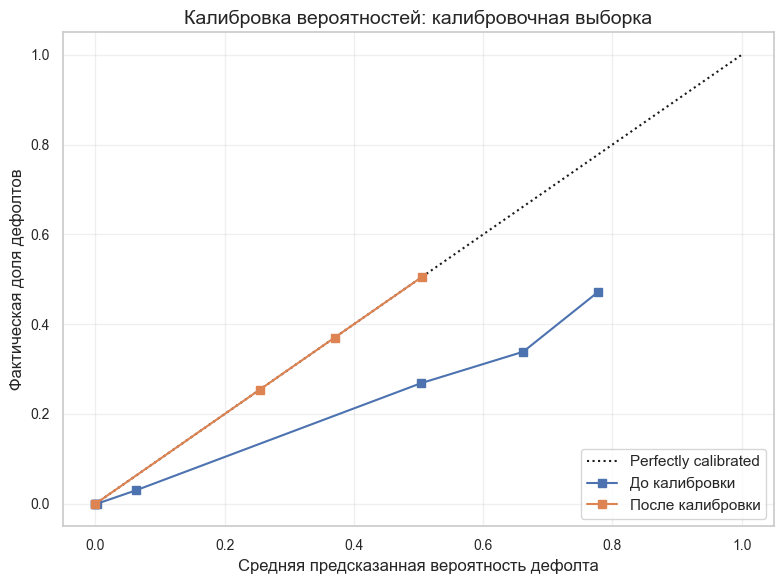

In [91]:
# Сравниваем вероятности до и после калибровки на cal_data
fig, ax = plt.subplots(figsize=(8, 6))

CalibrationDisplay.from_predictions(
    y_cal,
    proba_before,
    n_bins=10,
    strategy='quantile',
    name='До калибровки',
    ax=ax
)

CalibrationDisplay.from_predictions(
    y_cal,
    proba_after,
    n_bins=10,
    strategy='quantile',
    name='После калибровки',
    ref_line=False,
    ax=ax
)

# Диагональ соответствует совпадению вероятностей с частотой дефолтов
ax.set_title('Калибровка вероятностей: калибровочная выборка')
ax.set_xlabel('Средняя предсказанная вероятность дефолта')
ax.set_ylabel('Фактическая доля дефолтов')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [93]:
# Рассчитываем ошибку вероятностей: меньшее значение лучше
brier_results = pd.DataFrame({
    'модель': ['До калибровки', 'После калибровки'],
    'brier_score': [
        brier_score_loss(y_cal, proba_before),
        brier_score_loss(y_cal, proba_after)
    ]
})

display(brier_results)

# Показываем изменение: положительное значение означает снижение ошибки
brier_improvement = (
    brier_results.loc[0, 'brier_score']
    - brier_results.loc[1, 'brier_score']
)
print(f'Снижение ошибки Брайера: {brier_improvement:.6f}')

,модель,brier_score
0,До калибровки,0.095
1,После калибровки,0.068


Снижение ошибки Брайера: 0.027613


### <a id='toc1_10_2_'></a>[Выводы этапа калибровки](#toc0_)

До калибровки случайный лес завышал вероятность дефолта: кривая располагалась ниже диагонали. После изотонической калибровки предсказанные вероятности на калибровочной выборке стали соответствовать наблюдаемой частоте дефолтов — кривая практически совпала с диагональю.

Ошибка Брайера снизилась с 0,095 до 0,068, на 0,0276. Это свидетельствует об улучшении вероятностных оценок на калибровочной выборке. Поскольку калибратор обучался на этих же данных, результат требует подтверждения на тестовой выборке. Далее используем откалиброванную модель для подбора порога решения.

## <a id='toc1_11_'></a>[Поиск порога решения](#toc0_)

* Используя откалиброванную модель и калибровочную выборку, найдите порог, при котором будут достигнуты заданные в постановке задачи значения метрик:
    * approval rate — не менее 65%;
    * default rate — не более 2%;
    * missed defaults rate — не более 4%.
    
* Сделайте вывод о достигнутых в этом разделе результатах.

Подберём порог классификации на калибровочной выборке. Наблюдение считается одобренным, если вероятность дефолта ниже порога.

Проверим уникальные предсказанные вероятности и крайние варианты решений. Среди допустимых порогов выберем обеспечивающий максимальную долю одобрений.

### <a id='toc1_11_1_'></a>[Расчёт метрик для разных порогов](#toc0_)

In [99]:
# Получаем вероятности дефолта откалиброванной модели
proba_cal = calibrated_model.predict_proba(X_cal)[:, 1]
y_cal_array = y_cal.to_numpy()

# Проверяем все различные варианты разделения по вероятностям
# Порог выше 1 добавляем для проверки варианта «одобрить всех»
thresholds = np.unique(
    np.r_[0.0, proba_cal, np.nextafter(1.0, 2.0)]
)

# Считаем общее количество фактических дефолтов
total_defaults = (y_cal_array == 1).sum()
threshold_rows = []

for threshold in thresholds:
    # Одобряем наблюдения с вероятностью дефолта ниже порога
    approved = proba_cal < threshold

    # Считаем одобренные наблюдения и пропущенные дефолты
    approved_count = approved.sum()
    missed_defaults = ((y_cal_array == 1) & approved).sum()

    # Рассчитываем три бизнес-метрики
    threshold_rows.append({
        'threshold': threshold,
        'approval_rate': approved_count / len(y_cal_array),
        'default_rate': (
            missed_defaults / approved_count
            if approved_count > 0 else np.nan
        ),
        'missed_defaults_rate': (
            missed_defaults / total_defaults
            if total_defaults > 0 else np.nan
        )
    })

# Собираем результаты проверки порогов
threshold_results = pd.DataFrame(threshold_rows)


### <a id='toc1_11_2_'></a>[Выбор порога и проверка требований](#toc0_)

In [101]:
# Оставляем пороги, выполняющие все три требования
valid_thresholds = threshold_results.loc[
    (threshold_results['approval_rate'] >= 0.65)
    & (threshold_results['default_rate'] <= 0.02)
    & (threshold_results['missed_defaults_rate'] <= 0.04)
].copy()

# Сбрасываем результат предыдущего запуска
best_threshold = None
best_threshold_metrics = None

if not valid_thresholds.empty:
    # Выбираем максимальную долю одобрений среди допустимых вариантов
    best_threshold_metrics = valid_thresholds.sort_values(
        ['approval_rate', 'threshold'],
        ascending=[False, True]
    ).iloc[0]

    best_threshold = float(best_threshold_metrics['threshold'])
    print(f'Выбранный порог: {best_threshold:.8f}')

    # Форматируем проценты обычными строками, без использования style
    threshold_check = pd.DataFrame({
        'метрика': [
            'approval_rate', 'default_rate', 'missed_defaults_rate'
        ],
        'значение': [
            f"{best_threshold_metrics['approval_rate']:.2%}",
            f"{best_threshold_metrics['default_rate']:.2%}",
            f"{best_threshold_metrics['missed_defaults_rate']:.2%}"
        ],
        'требование': ['≥ 65%', '≤ 2%', '≤ 4%'],
        'выполнено': [
            best_threshold_metrics['approval_rate'] >= 0.65,
            best_threshold_metrics['default_rate'] <= 0.02,
            best_threshold_metrics['missed_defaults_rate'] <= 0.04
        ]
    })

    display(threshold_check)

else:
    # Сообщаем, если ни один порог не выполняет все требования
    print('Порог, выполняющий все три требования, не найден.')

    # Показываем вариант с минимумом пропущенных дефолтов при одобрении ≥ 65%
    diagnostic_result = threshold_results.loc[
        threshold_results['approval_rate'] >= 0.65
    ].sort_values(
        ['missed_defaults_rate', 'default_rate', 'approval_rate']
    ).head(1)

    display(diagnostic_result)

Выбранный порог: 0.26370989


,метрика,значение,требование,выполнено
0,approval_rate,69.64%,≥ 65%,True
1,default_rate,0.27%,≤ 2%,True
2,missed_defaults_rate,1.69%,≤ 4%,True


### <a id='toc1_11_3_'></a>[Выводы этапа поиска порога решений](#toc0_)

На калибровочной выборке выбран порог 0,26370989, обеспечивающий максимальную долю одобрений среди вариантов, выполняющих все ограничения:

- approval rate — 69,64% при требовании ≥ 65%;
- default rate — 0,27% при требовании ≤ 2%;
- missed defaults rate — 1,69% при требовании ≤ 4%.

Все три требования выполнены. Наблюдения с вероятностью дефолта ниже выбранного порога одобряются, остальные отклоняются. Порог фиксируется и далее применяется к тестовой выборке без дополнительного подбора.

## <a id='toc1_12_'></a>[Анализ матрицы ошибок](#toc0_)

* Оцените стабильность модели на тестовых данных. Для этого постройте:
    * матрицу ошибок на калибровочных данных;
    * матрицу классификации на тестовых данных.
* Сделайте вывод о моделях, рассчитав классические метрики машинного обучения и указанные в ТЗ бизнес-метрики.
* Сделайте вывод о стабильности модели.

Оценим модель с зафиксированным порогом на калибровочной и тестовой выборках. Построим матрицы ошибок и сравним классические и бизнес-метрики.

Класс 1 соответствует дефолту:
- TN — верно одобренные наблюдения без дефолта;
- FP — отклонённые наблюдения без дефолта;
- FN — одобренные наблюдения с дефолтом;
- TP — верно выявленные и отклонённые дефолты.

Калибровочная выборка использовалась для обучения калибратора и выбора порога, поэтому основная оценка качества проводится на тестовой выборке.

### <a id='toc1_12_1_'></a>[Предсказание матрицы ошибок](#toc0_)

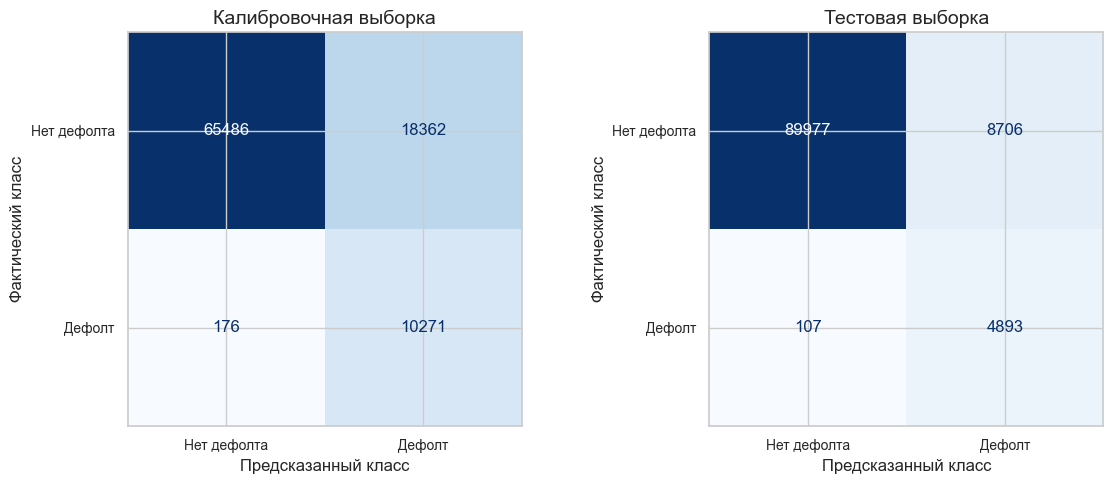

In [102]:
# Подготавливаем тестовые признаки и целевую переменную
X_test = test_data.drop(columns=['ID', 'target'])
y_test = test_data['target']

# Получаем вероятности одной и той же откалиброванной модели
proba_cal = calibrated_model.predict_proba(X_cal)[:, 1]
proba_test = calibrated_model.predict_proba(X_test)[:, 1]

# Применяем точное значение выбранного порога без округления
y_pred_cal = (proba_cal >= best_threshold).astype(int)
y_pred_test = (proba_test >= best_threshold).astype(int)

# Рассчитываем матрицы: строки — фактические классы, столбцы — прогноз
cm_cal = confusion_matrix(y_cal, y_pred_cal, labels=[0, 1])
cm_test = confusion_matrix(y_test, y_pred_test, labels=[0, 1])

# Показываем абсолютное количество наблюдений в каждой категории
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, cm, title in zip(
    axes,
    [cm_cal, cm_test],
    ['Калибровочная выборка', 'Тестовая выборка']
):
    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['Нет дефолта', 'Дефолт']
    ).plot(ax=ax, cmap='Blues', values_format='d', colorbar=False)

    ax.set_title(title)
    ax.set_xlabel('Предсказанный класс')
    ax.set_ylabel('Фактический класс')

plt.tight_layout()
plt.show()

### <a id='toc1_12_2_'></a>[Сравнение метрик](#toc0_)

In [104]:
# Рассчитываем одинаковый набор метрик для обеих выборок
def calculate_metrics(y_true, y_pred, y_proba):
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    return {
        'accuracy': accuracy_score(y_true, y_pred),
        'roc_auc': roc_auc_score(y_true, y_proba),
        'precision': precision_score(y_true, y_pred, zero_division=0),
        'recall': recall_score(y_true, y_pred, zero_division=0),
        'f1': f1_score(y_true, y_pred, zero_division=0),
        'brier_score': brier_score_loss(y_true, y_proba),
        'approval_rate': (tn + fn) / len(y_true),
        'default_rate': fn / (tn + fn) if tn + fn > 0 else np.nan,
        'missed_defaults_rate': fn / (tp + fn) if tp + fn > 0 else np.nan
    }


# Объединяем результаты в одну таблицу
evaluation_results = pd.DataFrame({
    'Калибровочная': calculate_metrics(y_cal, y_pred_cal, proba_cal),
    'Тестовая': calculate_metrics(y_test, y_pred_test, proba_test)
})

# Показываем изменение метрик на тесте относительно калибровочной выборки
evaluation_results['Изменение (тест − кал.)'] = (
    evaluation_results['Тестовая'] - evaluation_results['Калибровочная']
)

display(evaluation_results.round(4))

,Калибровочная,Тестовая,Изменение (тест − кал.)
accuracy,0.803,0.915,0.112
roc_auc,0.914,0.963,0.048
precision,0.359,0.360,0.001
recall,0.983,0.979,-0.005
f1,0.526,0.526,0.001
brier_score,0.068,0.030,-0.038
approval_rate,0.696,0.869,0.172
default_rate,0.003,0.001,-0.002
missed_defaults_rate,0.017,0.021,0.005


In [105]:
# Берём бизнес-метрики тестовой выборки
test_metrics = evaluation_results['Тестовая']

# Проверяем каждое ограничение без округления исходных значений
test_requirements = pd.DataFrame({
    'метрика': [
        'approval_rate',
        'default_rate',
        'missed_defaults_rate'
    ],
    'значение на тесте': [
        f"{test_metrics['approval_rate']:.2%}",
        f"{test_metrics['default_rate']:.2%}",
        f"{test_metrics['missed_defaults_rate']:.2%}"
    ],
    'требование': ['≥ 65%', '≤ 2%', '≤ 4%'],
    'выполнено': [
        test_metrics['approval_rate'] >= 0.65,
        test_metrics['default_rate'] <= 0.02,
        test_metrics['missed_defaults_rate'] <= 0.04
    ]
})

display(test_requirements)

,метрика,значение на тесте,требование,выполнено
0,approval_rate,86.88%,≥ 65%,True
1,default_rate,0.12%,≤ 2%,True
2,missed_defaults_rate,2.14%,≤ 4%,True


### <a id='toc1_12_3_'></a>[Выводы этапа анализа матрицы ошибок](#toc0_)

На тестовой выборке модель с зафиксированным порогом выявила 4893 из 5000 дефолтов, пропустив 107. При этом 8706 наблюдений без дефолта были ошибочно отклонены. Recall составил 0,979, precision — 0,360: модель обнаруживает почти все дефолты, но значительная часть отказов приходится на наблюдения без дефолта.

По сравнению с калибровочной выборкой ROC-AUC увеличился с 0,914 до 0,963, accuracy — с 0,803 до 0,915, ошибка Брайера снизилась с 0,068 до 0,030. Precision и F1 практически не изменились, recall снизился незначительно.

Все бизнес-требования на тесте выполнены:
- approval rate — 86,88% при требовании ≥ 65%;
- default rate — 0,12% при требовании ≤ 2%;
- missed defaults rate — 2,14% при требовании ≤ 4%.

На рассмотренном тестовом периоде модель сохранила высокую полноту выявления дефолтов и выполнила заданные ограничения без изменения порога. При этом улучшение части метрик нельзя полностью приписывать устойчивости модели: доля дефолтов в тестовой выборке ниже, чем в калибровочной, что влияет на результаты сравнения.

## <a id='toc1_13_'></a>[Фиксирование итоговой модели](#toc0_)

- Опишите лучшую модель и найденный порог классификации.


### <a id='toc1_13_1_'></a>[Описание модели](#toc0_)

Итоговая модель — случайный лес с RandomOverSampler и параметрами, подобранными Optuna: 79 деревьев, максимальная глубина 10, max_features='log2'. Пайплайн включает заполнение числовых пропусков медианой, масштабирование и One-Hot Encoding семейного положения.

Модель обучена на данных до 2018 года, вероятности откалиброваны изотонической регрессией на данных за 2018 год. На калибровочной выборке выбран порог около 0.26371: при вероятности не ниже порога прогнозируется дефолт и заявка отклоняется.

На тестовой выборке за 2019 год ROC-AUC составил 0.963. Доля одобрений — 86.88%, доля дефолтов среди одобренных — 0.12%, доля пропущенных дефолтов — 2.14%. Все три заданных ограничения выполнены.

Для дальнейшего использования сохраняем обученный пайплайн с калибровкой, точное значение порога, список входных столбцов и тестовые метрики.

### <a id='toc1_13_2_'></a>[Сохранение модели](#toc0_)

In [ ]:
# Сохраняем обученную модель и точный порог без повторного обучения
final_artifact = {
    'model': calibrated_model,
    'threshold': float(best_threshold),
    'feature_columns': X_train.columns.tolist(),
    'test_metrics': evaluation_results['Тестовая'].to_dict()
}

# Калиброванная модель уже содержит обученный пайплайн предобработки и лес
joblib.dump(final_artifact, 'final_scoring_model.joblib')

print('Модель и порог сохранены: final_scoring_model.joblib')
print(f'Порог классификации: {best_threshold:.8f}')

Модель и порог сохранены: final_scoring_model.joblib
Порог классификации: 0.26370989


In [107]:
# Проверяем загрузку сохранённой модели и выводим результат
try:
    final_artifact = joblib.load('final_scoring_model.joblib')
    final_model = final_artifact['model']
    final_threshold = final_artifact['threshold']
    feature_columns = final_artifact['feature_columns']

    print('Модель, порог и список признаков успешно загружены.')
    print(f'Порог классификации: {final_threshold:.8f}')

except Exception as error:
    # Показываем причину, если загрузка не удалась
    print(f'Ошибка загрузки: {error}')

Модель, порог и список признаков успешно загружены.
Порог классификации: 0.26370989


## <a id='toc1_14_'></a>[Анализ важности признаков](#toc0_)

* Проведите анализ важности признаков найденной модели на полных тренировочных данных.
* Используйте `feature_importances_` для найденной модели.
* Сделайте вывод о силе влияния признаков на дефолт.

### <a id='toc1_14_1_'></a>[Важность признаков](#toc0_)

In [108]:
# Извлекаем обученный лес и названия признаков после предобработки
forest = best_model.named_steps['model']
feature_names = best_model.named_steps['preprocessor'].get_feature_names_out()

# Собираем важности признаков и сортируем по убыванию
feature_importance = pd.DataFrame({
    'Признак': feature_names,
    'Важность': forest.feature_importances_
})

# Убираем технические префиксы преобразователей из названий
feature_importance['Признак'] = (
    feature_importance['Признак'].str.replace(r'^[^_]+__', '', regex=True)
)

feature_importance = (
    feature_importance
    .sort_values('Важность', ascending=False)
    .reset_index(drop=True)
)

display(feature_importance)

,Признак,Важность
0,MCC_5411,0.098
1,MCC_3990,0.074
2,MCC_5722,0.074
3,доход,0.074
4,MCC_другое,0.069
5,MCC_3990_rolling_3,0.069
6,MCC_5722_expanding_max,0.067
7,MCC_4900_expanding_max,0.062
8,MCC_5411_expanding_max,0.061
9,MCC_5812,0.052


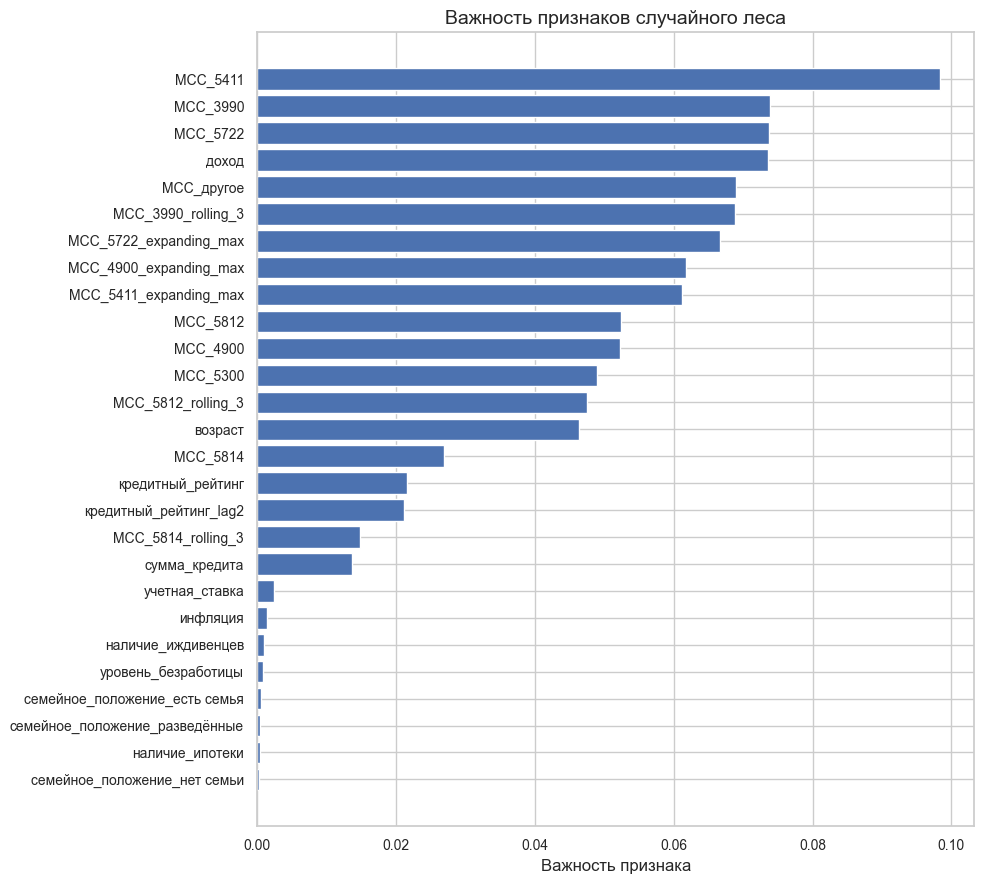

Пять наиболее важных признаков:


,Признак,Важность
0,MCC_5411,0.098
1,MCC_3990,0.074
2,MCC_5722,0.074
3,доход,0.074
4,MCC_другое,0.069


Суммарная важность пяти ведущих признаков: 38.9%


In [109]:
# Показываем важность всех признаков на горизонтальной диаграмме
plot_data = feature_importance.sort_values('Важность')

plt.figure(figsize=(10, 9))
plt.barh(plot_data['Признак'], plot_data['Важность'])
plt.title('Важность признаков случайного леса')
plt.xlabel('Важность признака')
plt.ylabel('')
plt.tight_layout()
plt.show()

# Выводим лидирующие признаки и их суммарную важность
print('Пять наиболее важных признаков:')
display(feature_importance.head(5))

print(
    'Суммарная важность пяти ведущих признаков: '
    f"{feature_importance.head(5)['Важность'].sum():.1%}"
)

### <a id='toc1_14_2_'></a>[Выводы этапа Анализа важности признаков](#toc0_)

Наибольшую важность в выбранной модели имеют MCC_5411 (9.8%), MCC_3990, MCC_5722 и доход (примерно по 7.4%), а также MCC_другое (6.9%). Вместе эти пять признаков составляют 38.9% общей важности. Таким образом, модель преимущественно опирается на расходы клиентов и их доход.

Созданные временные признаки также активно используются: MCC_3990_rolling_3 имеет важность 6.9%, а накопленные максимумы расходов MCC_5722, MCC_4900 и MCC_5411 — около 6–7% каждый. Это показывает, что история расходов участвует в прогнозировании наряду со значениями за отдельный месяц.

Кредитный рейтинг и его лаг имеют меньшую важность — около 2.2% и 2.1%. Макроэкономические показатели, семейное положение, наличие иждивенцев и ипотеки вносят минимальный вклад в решения данного леса.

## <a id='toc1_15_'></a>[Выводы по проекту](#toc0_)

Сделайте выводы по проекту. Можете использовать такой план:

1. Цель и задачи исследования.

2. Подготовка данных и выборок.

3. Поиск и настройка модели.

4. Калибровка вероятностей.

5. Оптимизация бизнес-порога.

6. Анализ важности признаков.

7. Финальный пайплайн.

8. Основные выводы и рекомендации для бизнеса.



В ходе проекта разработана модель поведенческого скоринга для прогнозирования дефолта клиента в течение следующих 365 дней. Задача заключалась в выявлении клиентов с риском просрочки от 90 дней и выборе порога решения, обеспечивающего долю одобрений не менее 65%, долю дефолтов среди одобренных не более 2% и долю пропущенных дефолтов не более 4%.

На этапе исследовательского анализа изучены сведения о клиентах, кредитах, транзакциях, кредитном рейтинге, ипотеке и макроэкономических показателях за 2013–2019 годы. В исходных таблицах отсутствовали пропуски и полные дубликаты. Расходы по MCC-категориям характеризовались выраженной правосторонней асимметрией: средние значения заметно превышали медианы. Высокие значения расходов не удалялись автоматически, поскольку сами по себе не свидетельствуют об ошибках. Ипотечная таблица содержала только записи о наличии ипотеки, поэтому значение 1 во всех её строках соответствовало структуре источника.

Данные объединены в таблицу наблюдений «клиент — дата оценки». Для динамических показателей использованы значения предыдущего месяца, а наличие ипотеки определялось с учётом даты её открытия. Дополнительно созданы лаг кредитного рейтинга, скользящие средние расходов за три месяца и накопленные максимумы расходов. Эти признаки позволяют учитывать предшествующую историю клиента. Пропуски, возникающие после объединения и при недостаточной длине истории, обрабатывались в пайплайне.

Выборки разделены по времени: данные до 2018 года использовались для обучения и подбора параметров, 2018 год — для калибровки и выбора порога, 2019 год — для итогового тестирования. Внутри тренировочной выборки применена GroupTimeSeriesSplit с тремя фолдами, годовым периодом валидации и расширяющимся обучающим окном. Числовые признаки заполнялись медианой и масштабировались, семейное положение кодировалось One-Hot Encoding, бинарные признаки передавались без изменений. Предобработка и балансировка выполнялись внутри обучающей части каждого фолда.

Сравнивались логистическая регрессия и случайный лес без балансировки, а также с RandomOverSampler, SMOTE, RandomUnderSampler и комбинированным подходом. Случайный лес с оверсемплингом показал высокий ROC-AUC среди базовых вариантов — около 0.898. Для него выполнен подбор параметров Optuna с минимизацией доли пропущенных дефолтов. Оптимизация всех вариантов леса оказалась вычислительно затратной, поэтому поиск был сосредоточен на одном перспективном варианте. Итоговые параметры: 79 деревьев, максимальная глубина 10 и max_features='log2'.

После настройки средняя доля пропущенных дефолтов на кросс-валидации составила около 16.8%. При этом ROC-AUC был около 0.881: выбранная модель обеспечивала более полное выявление дефолтов при стандартном пороге, хотя не была лидером по ROC-AUC. Это соответствовало приоритету проекта — ограничению пропущенных дефолтов.

Выбранный пайплайн обучен на всей тренировочной выборке. Затем на данных за 2018 год выполнена изотоническая калибровка вероятностей. Brier score на калибровочной выборке снизился примерно с 0.095 до 0.068. Поскольку эта выборка использовалась для настройки калибратора, полученное улучшение рассматривалось как диагностический результат; независимая оценка проводилась на тестовых данных.

На калибровочной выборке выбран порог около 0.26371, максимизирующий долю одобрений при выполнении заданных ограничений. При вероятности дефолта не ниже порога заявка отклоняется. На калибровочных данных доля одобрений составила 69.64%, доля дефолтов среди одобренных — 0.27%, доля пропущенных дефолтов — 1.69%.

На тестовой выборке за 2019 год модель с зафиксированным порогом выполнила все бизнес-требования:
- доля одобрений — 86.88% при требовании не менее 65%;
- доля дефолтов среди одобренных — 0.12% при ограничении 2%;
- доля пропущенных дефолтов — 2.14% при ограничении 4%.

Тестовый ROC-AUC составил 0.963, accuracy — 0.915, recall — 0.979, precision — 0.360, F1 — 0.526, Brier score — около 0.030. Модель выявила 4893 из 5000 дефолтов и пропустила 107. При этом 8706 наблюдений без дефолта были ошибочно отнесены к рискованным. Таким образом, высокая полнота выявления дефолтов сопровождается ложными отказами, которые необходимо учитывать при оценке экономической эффективности решения. Более высокие значения части тестовых метрик также следует рассматривать с учётом изменения состава выборки и доли дефолтов.

Анализ feature_importances_ показал, что модель преимущественно использует расходы клиентов и доход. Наиболее важны MCC_5411, MCC_3990, MCC_5722, доход и MCC_другое: суммарно на них приходится 38.9% важности. Заметный вклад вносят скользящее среднее MCC_3990 и накопленные максимумы расходов MCC_5722, MCC_4900 и MCC_5411. Макроэкономические показатели, семейное положение и бинарные признаки имеют значительно меньшую важность. Эти оценки характеризуют использование признаков данным лесом, но не определяют направление влияния на риск и не доказывают причинную связь.

Обученная модель сохранена вместе с предобработкой, калибратором, точным порогом классификации, перечнем входных столбцов и тестовыми метриками. Загрузка сохранённого объекта позволяет использовать модель без повторного обучения.

В рамках проведённой проверки получено решение, удовлетворяющее всем трём бизнес-ограничениям на отложенном периоде. Для дальнейшего применения рекомендуется контролировать долю одобрений, дефолты среди одобренных, пропущенные дефолты и качество калибровки на новых данных. Отдельное направление развития — оценка стоимости ложных отказов и пропущенных дефолтов, чтобы выбирать порог с учётом финансового результата, а не только установленных ограничений.